# Theta_reg analysis, rare vs typical events: September runs without the near-copy statistics

Copy of `turb_theta_reg_rare_typical_sep.ipynb` (zfloor, full set of statistics) for the runs launched on 2026-10-01 with
the three near-copy pairs of statistics removed:

- **`L_6_psi` removed entirely** (`L_6[7]`/`L_6[8]` and `L_6_psi[20]`/`L_6_psi[21]` were near copies of each other);
- **one slot of `Scalar_morlet_gaussianK` dropped**, channel 8 region 3 (`--drop_stats Scalar_morlet_gaussianK:8:3`), the near copy of `Scalar_psi_gaussianK[77]`.

Two arms, 5 seeds each (900-904), choose with `ARM` in the config cell: `reg1e-4` (array job 465148) and `reg1e-2` (array job 465149).

What changes compared to the full-set notebook:
- `terms` (read from `config.json`) has no `L_6_psi`, so every family after `L_6` sits at different columns. Nothing below uses hard-coded column numbers: all ranges come from `theta_column_map` on the loaded potentials.
- The dropped slot is not re-applied by hand. The saved fitted state of `Scalar_morlet_gaussianK` already excludes it (`active_flat`), so loading it gives the reduced φ directly. The loader **checks** that the loaded `drop_slots` are the ones in `config.json`.
- These runs were launched with `--skip_reg_solve` and no offline solve has been done yet, so `LAM = None`: everything uses the sampler's $\theta_t$ at the last step (`THETA_SOURCE = 'theta_t'`), as in the July notebook.

Two sources of spread are reported: **across seeds** (every seed sees the same data `x1`) and a **bootstrap over the rare signals** (which signals happen to be rare).

**How to use.** Settings are in the **Knobs** cell. After changing a knob, re-run from the *Whole-dataset rare/typical split* cell down.

**Contents.** θ per family · load θ + potentials · rare/typical split (+ examples of each) · per-family energy by category · log p rare vs typical · Florentin's plot · 1. per-family gap D · 2. threshold robustness · 3. continuous version · 4. compensation · 5. residual variance · 6. model samples


In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
import sys, os, re, math
from types import SimpleNamespace

root = Path().resolve()
sys.path.insert(0, str(root / '../codes'))
from sde_routines import *
from utils import *
from utils_experiment import *
from filters_bank import *
from potentials import *
from ortho_wavelet import *
from check_potentials import *  # theta_column_map, decode_mod2_stq, etc.

sys.path.insert(0, str(root / '../data'))
from data_loader import *

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device, '|', root)

pd.set_option('display.float_format', lambda x: f'{x:.3g}')

%matplotlib inline

device: cuda | /lustre/fswork/projects/rech/wbg/ukv59en/MGD-for-Maximum-Entropy-Generation/turbulence


## Knobs

Change these, then re-run from the rare/typical split cell onward.

In [2]:
# --- rare/typical split ---
PERCENTILE = 95                  # a signal is 'rare' if its max |lag-1 increment| is above this percentile of x1
                                 # (95 -> top 5% of signals rare, 99 -> top 1%)
ROBUSTNESS_PERCENTILES = [95, 99, 99.5]   # section 2; PERCENTILE is added automatically

# --- examples of typical / rare signals (cell right after the split) ---
N_EVENT_EXAMPLES = 8             # signals shown per category
EVENT_PICK = 'random'            # 'random': random draw within each category; 'extreme': rare = the most extreme,
                                 #   typical = the least extreme
EVENT_SEED = 0

# --- zoom panel in the per-family energy cell ---
ZOOM_FAMILIES = ['Scattering_Fourth_Order_Mod2_Real_Q1', 'Scattering_Fourth_Order_Mod2_Imag_Q1', 'TOTAL']

# --- Florentin's plot (signals ordered by log p) ---
N_EXAMPLES = 32                  # wraps at 8 per row
EXAMPLE_SPACING = 'quantile'     # 'quantile': equally spaced in rank of log p (every panel a distinct signal,
                                 #   insensitive to outliers); 'linear': equally spaced in log p value
EXAMPLE_RANGE = (0.5, 99.5)      # percentiles of log p the examples are drawn from; (0, 100) = full range
EXAMPLE_SHAREY = True            # same y-axis for every panel

# --- bootstraps over the rare signals (sections 1 and 5) ---
N_BOOT = 1000
BOOT_SEED = 0

In [3]:
import os

# LOCAL vs JEAN ZAY -- load_turbulence_1d()'s default path in data_loader.py
# is Jean-Zay-only (/lustre/...). Flip to "jean_zay" there instead of editing this.
# PHI_CHUNK_SIZE batches phi(x)/grad(x) evaluation over the sample dim -- evaluating
# Scattering_Fourth_Order_Mod2_{Real,Imag}_Q1 on the full n1=5000 batch at once
# materializes a ~5.9GB intermediate BEFORE any reduction (measured directly:
# DefaultCPUAllocator asked for exactly 5898240000 bytes) -- chunking avoids it
# with no change to the result. Jean Zay has enough RAM/GPU memory to skip it.
RUN_LOCATION = "jean_zay"   # "local" or "jean_zay"

if RUN_LOCATION == "local" and torch.cuda.is_available():
    # A fixed chunk_size=500 assumes a GPU mostly to ourselves. On a GPU shared with
    # other processes (measured here: a co-tenant job holding ~19.5/22GB, leaving as
    # little as ~40MB free) that assumption breaks and 500 alone can still OOM. The
    # ~5.9GB/5000-sample intermediate above scales to ~1.2MiB/sample, so size the
    # chunk from what's ACTUALLY free right now (measured before potentials/data are
    # loaded, so this slightly overestimates later headroom -- the 2x margin covers
    # that plus the other job's usage not being static).
    free_bytes, _ = torch.cuda.mem_get_info()
    BYTES_PER_SAMPLE = 1.2 * 1024 ** 2
    PHI_CHUNK_SIZE = max(1, int(free_bytes / BYTES_PER_SAMPLE / 2))
    print(f"GPU free memory: {free_bytes / 1e6:.0f}MB -> PHI_CHUNK_SIZE = {PHI_CHUNK_SIZE}")
else:
    PHI_CHUNK_SIZE = 500 if RUN_LOCATION == "local" else None

if RUN_LOCATION == "local":
    local_turbulence_path = (root / "../data/data_files/turbulence_1d_period.pt").resolve()
    if local_turbulence_path.exists():
        os.environ["TURBULENCE_1D_DATA_PATH"] = str(local_turbulence_path)
    else:
        print(f"WARNING: {local_turbulence_path} not found -- load_turbulence_1d() "
              f"will fall back to its Jean Zay default path and fail locally.")
print(f"RUN_LOCATION = {RUN_LOCATION!r}, PHI_CHUNK_SIZE = {PHI_CHUNK_SIZE!r}")

RUN_LOCATION = 'jean_zay', PHI_CHUNK_SIZE = None


In [4]:
import json

ARM = 'reg1e-4'      # 'reg1e-4' (array job 465148) or 'reg1e-2' (array job 465149)
GROUP = ('turbulencesynth_M256_J8_Q3_sigma3.5_nt60000_n1_8500_lam0.0_thomas_nsub1_moment_f64_dedupfilt1e-08'
         f'_terms54d17f3b_zfloor_two_phase_noL6psi_noSm30_{ARM}')
RUN = ('turbulencesynth_M256_J8_Q3_sigma3.5_nt60000_n1_8500_lam0.0_thomas_nsub1_moment_f64_dedupfilt1e-08'
       '_seed_{seed}_terms54d17f3b_zfloor_two_phase_noL6psi_noSm30_' + ARM + '_{ts}')
CONFIGS = [RUN.format(seed=s, ts='20261001_1911') for s in (900, 901, 902, 903, 904)]
LAM = 1e-3       # lam of an offline Theta_reg solve; None = none done yet for these runs (they ran --skip_reg_solve)
RIDGE = {'reg1e-4': 1e-4, 'reg1e-2': 1e-2}[ARM]   # as in launch/resolve_lamsweep.sh
LAM_LABEL = 'theta_t (no Theta_reg)' if LAM is None else f'lam={LAM:g}'

sweep_root = Path(os.environ['SCRATCH']) / 'MGD-for-Maximum-Entropy-Generation/turbulence/theta_reg_lamsweep_xseed'

exp_dir_by_seed, cfg_by_seed, config_by_seed, theta_path_by_seed = {}, {}, {}, {}
for config in CONFIGS:
    exp_dir = root / 'experiments' / GROUP / config
    assert exp_dir.is_dir(), f'missing {exp_dir}'
    cfg = json.loads((exp_dir / 'config.json').read_text())
    key = f"seed{cfg['seed']}"
    exp_dir_by_seed[key], cfg_by_seed[key], config_by_seed[key] = exp_dir, cfg, config
    solved = sorted((sweep_root / config).glob('lam*_ridge*.pt'))
    print(f"{key}: offline Theta_reg solves: {[p.stem for p in solved] or 'none'}")
    theta_path_by_seed[key] = sweep_root / config / f'lam{LAM:g}_ridge{RIDGE:g}_moment_mask.pt' if LAM is not None else None

missing = [str(p) for p in theta_path_by_seed.values() if p is None or not p.exists()]
HAVE_REG = LAM is not None and not missing
print(f"HAVE_REG = {HAVE_REG}" + ('' if HAVE_REG else f"  (LAM={LAM}; missing: {missing})"))

seed_keys = sorted(cfg_by_seed, key=lambda s: int(s.replace('seed', '')))
cfg = cfg_by_seed[seed_keys[0]]
skip = {'timestamp', 'config_name', 'seed'}
for k in seed_keys[1:]:
    diff = {q for q in set(cfg) | set(cfg_by_seed[k]) if q not in skip and cfg.get(q) != cfg_by_seed[k].get(q)}
    assert not diff, f'{k} differs from {seed_keys[0]} in {diff}'
print(f"{len(seed_keys)} seeds {seed_keys}, identical config.json apart from seed/timestamp")

J, Q, M = cfg['J'], cfg['Q'], cfg['M']
sigma, nt, n1 = cfg['sigma'], cfg['nt'], cfg['n1']
terms = cfg['terms']     # this order is the theta column order
DROP_STATS = cfg.get('drop_stats') or []
print('terms:', terms)
print('drop_stats:', DROP_STATS)

W = DefineWavelet('Db', m=3, device=device)
Data = load_turbulence_1d().to(device)
Data = split_periodize_reshape(Data, cfg['subseries_len'])
for j in range(int(np.log2(cfg['subseries_len'] / cfg['target_len']))):   # as run_SDE.py
    Data = W.decompose(Data)[1]

x1 = normalize(Data[:n1])
assert tuple(x1.shape[1:]) == (1, M)
print('Data shape:', Data.shape, '| x1 shape:', x1.shape)

seed900: offline Theta_reg solves: ['lam0.0001_ridge0.0001_moment_mask', 'lam0.001_ridge0.0001_moment_mask', 'lam0.01_ridge0.0001_moment_mask', 'lam0.1_ridge0.0001_moment_mask', 'lam0_ridge0.0001_moment_mask', 'lam100_ridge0.0001_moment_mask', 'lam10_ridge0.0001_moment_mask', 'lam1_ridge0.0001_moment_mask', 'lam1e-05_ridge0.0001_moment_mask', 'lam1e-06_ridge0.0001_moment_mask']
seed901: offline Theta_reg solves: ['lam0.0001_ridge0.0001_moment_mask', 'lam0.001_ridge0.0001_moment_mask', 'lam0.01_ridge0.0001_moment_mask', 'lam0.1_ridge0.0001_moment_mask', 'lam0_ridge0.0001_moment_mask', 'lam100_ridge0.0001_moment_mask', 'lam10_ridge0.0001_moment_mask', 'lam1_ridge0.0001_moment_mask', 'lam1e-05_ridge0.0001_moment_mask', 'lam1e-06_ridge0.0001_moment_mask']
seed902: offline Theta_reg solves: ['lam0.0001_ridge0.0001_moment_mask', 'lam0.001_ridge0.0001_moment_mask', 'lam0.01_ridge0.0001_moment_mask', 'lam0.1_ridge0.0001_moment_mask', 'lam0_ridge0.0001_moment_mask', 'lam100_ridge0.0001_moment_m

In [5]:
REAL_KEY = "Scattering_Fourth_Order_Mod2_Real_Q1"
IMAG_KEY = "Scattering_Fourth_Order_Mod2_Imag_Q1"
COMPLEX_NAME = "Scattering_Fourth_Order_Mod2_Q1"

potential_colors = {
    "L_6": "tab:blue",
    "L_6_psi": "tab:olive",
    "L_2_lowpass": "tab:green",
    "Scattering_Fourth_Order_Mod2_Real_Q1": "tab:red",
    "Scattering_Fourth_Order_Mod2_Imag_Q1": "tab:purple",
    "Scalar_psi_gaussianK": "tab:orange",
    "Scalar_morlet_gaussianK": "tab:cyan",
}

In [6]:
import gc

def load_potentials_for_config(exp_dir, cfg, device):
    """The run's potentials, built as run_experiment builds them (same terms order and
    filter deduplication), with each fitted state loaded from exp_dir/fitted_potentials."""
    M, J, Q = cfg['M'], cfg['J'], cfg['Q']
    filters, filters_Phi = return_Filters(M, J, 1, device=device, include_phi=True)
    filters_Q = return_Filters(M, J, Q, device=device)
    potentials = get_1d_potentials(cfg['terms'], J, filters, Q, scalar_param=None, parallel=False,
                                     filters_Q=filters_Q, filters_Phi=filters_Phi,
                                     deduplicate_filters=cfg.get('deduplicate_filters', False),
                                     dedup_tol=cfg.get('dedup_tol', 1e-12))
    resolved_config = exp_dir.name
    potentials_dir = Path(exp_dir) / "fitted_potentials"
    if not potentials_dir.exists():
        raise FileNotFoundError(f"No fitted_potentials dir for {resolved_config} at {potentials_dir}")
    for name, p in potentials.items():
        p.to(device)
        if not hasattr(p, "is_fitted"):
            continue
        state_path = potentials_dir / f"{name}.pt"
        if not state_path.exists():
            raise FileNotFoundError(f"[{name}] missing fitted state at {state_path}")
        own_filters = p.filters
        loaded = type(p).load_fixed_parameters(state_path, own_filters, map_location=device)
        loaded.to(device)
        potentials[name] = loaded
    # The dropped (channel, region) slots are already excluded from the saved active_flat;
    # check that the state on disk is the one config.json says was run.
    expected = {}
    for spec in cfg.get('drop_stats') or []:      # NAME:CHANNEL:REGION, as run_experiment parses it
        name, ch, reg = spec.split(':')
        expected.setdefault(name, set()).add((int(ch), int(reg)))
    for name, p in potentials.items():
        got = {tuple(map(int, s)) for s in getattr(p, 'drop_slots', ())}
        assert got == expected.get(name, set()), \
            f'[{name}] fitted state has drop_slots {sorted(got)}, config.json says {sorted(expected.get(name, set()))}'
        if got:
            J_p = p.J
            assert not any(int(k) * J_p + int(j) in set(p.active_flat.tolist()) for j, k in got), \
                f'[{name}] a dropped slot is still in active_flat'
    return potentials

def _chunked_call(one_chunk_fn, x, chunk_size):
    """Run one_chunk_fn over x in chunks of chunk_size, halving a chunk and
    retrying if it OOMs, instead of trusting chunk_size as exact (it's only ever a
    starting guess -- see PHI_CHUNK_SIZE's cell for why).

    The retry must happen AFTER leaving the except block, not from inside it: while
    Python is still inside an `except` clause, the caught exception's traceback stays
    alive, and a live traceback pins every local variable in the frame that raised it
    -- including whatever CUDA tensor torch.fft had already allocated right before the
    allocator gave up. Recursing from inside the except (as an earlier version of this
    function did) meant those tensors were never released, so retries made memory
    usage climb instead of shrink -- measured directly: our own process's GPU memory
    grew monotonically (622MiB -> 2.7GiB) across repeated halving instead of the
    freed chunk's memory coming back, and the recursion still failed even at a single
    sample. Exiting the except block first lets gc.collect() actually reclaim them."""
    def _try(x_sub):
        try:
            return one_chunk_fn(x_sub)
        except torch.cuda.OutOfMemoryError:
            if x_sub.shape[0] <= 1:
                raise
        # Outside the except block now -- the failed attempt's traceback (and
        # whatever it was pinning) is no longer referenced from here.
        gc.collect()
        torch.cuda.empty_cache()
        mid = x_sub.shape[0] // 2
        return torch.cat([_try(x_sub[:mid]), _try(x_sub[mid:])], dim=0)

    if chunk_size is None or x.shape[0] <= chunk_size:
        return _try(x)
    chunks = []
    for i in range(0, x.shape[0], chunk_size):
        chunks.append(_try(x[i:i + chunk_size]))
        if torch.cuda.is_available():
            gc.collect()
            torch.cuda.empty_cache()
    return torch.cat(chunks, dim=0)

def compute_phi_X(potentials, x, chunk_size=PHI_CHUNK_SIZE):
    # Each chunk's result moves to CPU before the next chunk starts (see
    # compute_phi_grad_X's docstring for why -- same reasoning, phi(x) is just much
    # smaller than grad(x) so it mattered less here, but keeping both consistent).
    def _one_chunk(x_chunk):
        feats = []
        for p in potentials.values():
            feat = p(x_chunk)
            if feat.ndim == 1:
                feat = feat.unsqueeze(1)
            feats.append(feat)
        return torch.cat(feats, dim=-1).detach().cpu()
    return _chunked_call(_one_chunk, x, chunk_size)

def compute_phi_grad_X(potentials, x, chunk_size=PHI_CHUNK_SIZE):
    """Concatenate each potential's own analytic grad(x) along the coefficient axis
    -> (n, d, T): the exact object the MGD force field is built from (compare
    sde_routines.py's grad_potential = torch.cat((grad_potential, potential.grad(x)),
    dim=1)), NOT a generic autograd Jacobian -- several potentials here wrap forward()
    in torch.no_grad(), so autograd through forward() wouldn't work anyway.

    Each chunk is moved to CPU (and the CUDA cache emptied) right after it's computed,
    before the next chunk starts, and _chunked_call halves+retries any chunk that
    still OOMs -- see its docstring for why a single precomputed chunk_size can't be
    trusted on a shared GPU, and why the retry must happen outside the except block.
    Output values are unchanged; only the device changes."""
    def _one_chunk(x_chunk):
        grad_potential = None
        for p in potentials.values():
            g = p.grad(x_chunk)
            grad_potential = g if grad_potential is None else torch.cat((grad_potential, g), dim=1)
        return grad_potential.detach().cpu()
    return _chunked_call(_one_chunk, x, chunk_size)

## θ per family at the last node: MGD vs θ_reg

Mean over seeds ± std (shaded). MGD θ is `lagrange_multipliers/<config>.pt[-1]`, shown opaque; θ_reg (if `LAM` is set and solved) is shown in the same color, faded.

seed900: theta_t (60000, 258) -> last step
seed901: theta_t (60000, 258) -> last step
seed902: theta_t (60000, 258) -> last step
seed903: theta_t (60000, 258) -> last step
seed904: theta_t (60000, 258) -> last step
[deduplicate_filters] filters_Q: 25 -> 22 channels for channel-list potentials (dropped duplicates [21, 22, 23], tol=1e-08)


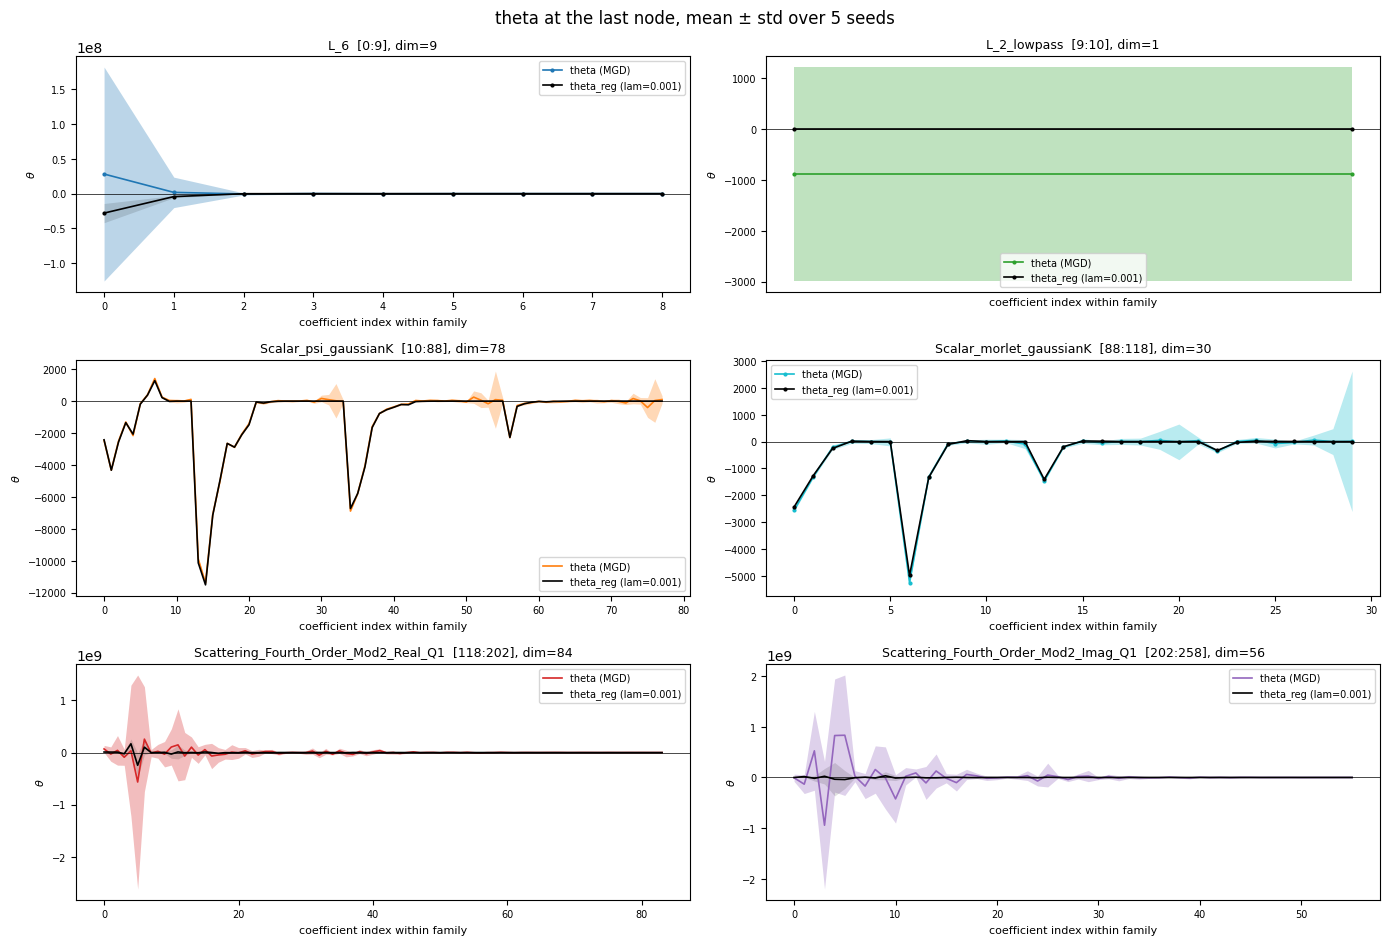

per seed L6 coefficients:
[[-2.284e+07 -3.279e+06 -8.429e+04  1.560e+03  1.856e+03 -2.324e+01
  -1.264e+02 -1.851e+01  2.542e-03]
 [-1.168e+07 -6.772e+06 -1.135e+05 -5.718e+02  1.460e+03 -3.538e+01
   1.224e+01  3.463e+01  2.476e-03]
 [-4.091e+07 -4.289e+06 -4.609e+04 -1.590e+03 -1.694e+02  1.224e+01
   8.120e+01  1.419e+01 -1.188e-03]
 [-4.369e+07 -2.638e+06 -3.939e+04 -1.468e+03  4.978e+02  3.270e+02
   2.722e+02  2.391e+01 -5.751e-04]
 [-2.053e+07 -4.187e+06 -8.011e+04 -2.131e+02  1.041e+03  7.800e+01
   1.836e+02 -1.534e+01  5.580e-04]]
average across seeds:
[-2.79295067e+07 -4.23290383e+06 -7.26688003e+04 -4.56650302e+02
  9.36966027e+02  7.17263355e+01  8.45723874e+01  7.77375196e+00
  7.62647488e-04]


In [45]:
def _saved(kind, config):
    """saved_results/<kind>/<config>[.pt], or None if neither exists."""
    p = root / 'saved_results' / kind / config
    return next((q for q in (p.with_name(p.name + '.pt'), p) if q.exists()), None)

theta_mgd_by_seed, theta_reg0_by_seed = {}, {}
for key in seed_keys:
    path = _saved('lagrange_multipliers', config_by_seed[key])
    assert path is not None, f'{key}: no saved_results/lagrange_multipliers/{config_by_seed[key]}[.pt]'
    theta_t = torch.load(path, map_location='cpu')
    theta_mgd_by_seed[key] = theta_t[-1].double().numpy()
    print(f"{key}: theta_t {tuple(theta_t.shape)} -> last step")
    del theta_t
    if HAVE_REG:
        theta_reg0_by_seed[key] = torch.load(theta_path_by_seed[key], map_location='cpu',
                                             weights_only=False)['Theta_reg'][-1].double().numpy()

theta_sets = {'theta (MGD)': np.stack([theta_mgd_by_seed[k] for k in seed_keys])}   # (n_seeds, d)
if HAVE_REG:
    theta_sets[f'theta_reg (lam={LAM:g})'] = np.stack([theta_reg0_by_seed[k] for k in seed_keys])
assert len({v.shape for v in theta_sets.values()}) == 1, {k: v.shape for k, v in theta_sets.items()}
d_theta = theta_sets['theta (MGD)'].shape[1]

_pots0 = load_potentials_for_config(exp_dir_by_seed[seed_keys[0]], cfg_by_seed[seed_keys[0]], device)
family_ranges0 = {name: (a, a + w) for name, (a, w) in theta_column_map(_pots0, d_theta).items()}
del _pots0

# (line alpha, band alpha): MGD opaque, theta_reg the same color but faded
STYLE = {'theta (MGD)': (1.0, 0.30), 'theta_reg': (1.0, 0.12)}
n_cols = 2
n_rows = math.ceil(len(family_ranges0) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(7 * n_cols, 3.2 * n_rows), squeeze=False)
for i, (F, (a, b)) in enumerate(family_ranges0.items()):
    ax = axes[i // n_cols][i % n_cols]
    color = potential_colors.get(F, f'C{i}')
    idx = np.arange(b - a)
    for label, th in theta_sets.items():
        is_reg = label.startswith('theta_reg')
        la, fa = STYLE['theta_reg' if is_reg else label]
        c = 'k' if is_reg else color
        mean = th[:, a:b].mean(0)
        std = th[:, a:b].std(0, ddof=1) if th.shape[0] > 1 else np.zeros(b - a)
        # a 1-coefficient family would give a zero-width band: widen it to +-0.3 around 0
        xs, mean, std = (np.array([-0.3, 0.3]), mean.repeat(2), std.repeat(2)) if b - a == 1 else (idx, mean, std)
        ax.plot(xs, mean, color=c, alpha=la, lw=1.2, marker='.' if b - a < 40 else None, ms=4, label=label)
        ax.fill_between(xs, mean - std, mean + std, color=c, alpha=fa, lw=0)
    if b - a == 1:
        ax.set_xticks([])
    ax.axhline(0, color='k', lw=0.5)
    ax.set_title(f'{F}  [{a}:{b}], dim={b - a}', fontsize=9)
    ax.set_xlabel('coefficient index within family', fontsize=8)
    ax.set_ylabel(r'$\theta$', fontsize=8)
    ax.tick_params(labelsize=7)
    ax.legend(fontsize=7)
for j in range(len(family_ranges0), n_rows * n_cols):
    axes[j // n_cols][j % n_cols].axis('off')
fig.suptitle(f'theta at the last node, mean ± std over {len(seed_keys)} seeds'
             + ('' if HAVE_REG else '  (no theta_reg: LAM unset or not solved)'))
fig.tight_layout(); plt.show()

print("per seed L6 coefficients:") 
print(np.array2string(theta_sets['theta_reg (lam=0.001)'][:, 0:9], precision=3))   # 5 seeds x 9 L_6 coefficients
print("average across seeds:") 
print(np.array2string(theta_sets['theta_reg (lam=0.001)'][:, 0:9].mean(axis=0)))

## Load Theta_reg (final node) and the fitted potentials, per seed

`Theta_reg[-1]` = the regularised θ at the last node of the grid (the two_phase grid is the same for every seed). `theta_t`/MGD is never used.

The fitted potentials are fitted on `x1`, the same for every seed, so they should agree across seeds. This is **checked**, not assumed: φ of each seed's potentials on the first `N_CHECK` signals is compared with the reference seed's. If they all agree, one `phi_X` is shared. Otherwise each seed gets its own `phi_X` (the rest of the notebook works either way).

In [21]:
THETA_SOURCE = 'theta_t'      # 'theta_t': the sampler's theta at the last step (as the July notebook)
                              # 'theta_reg': offline Theta_reg[-1] from lam<LAM>_ridge<RIDGE>.pt
assert THETA_SOURCE == 'theta_t' or HAVE_REG, 'set LAM to a value solved for every seed'
N_CHECK = 200

theta_by_seed, potentials_by_seed = {}, {}
for key in seed_keys:
    if THETA_SOURCE == 'theta_t':
        theta_by_seed[key] = theta_mgd_by_seed[key]               # loaded in the theta-per-family cell
        print(f"{key}: theta_t[-1] from lagrange_multipliers")
    else:
        sol = torch.load(theta_path_by_seed[key], map_location='cpu', weights_only=False)
        assert sol['config'] == config_by_seed[key]
        theta_by_seed[key] = sol['Theta_reg'][-1].double().numpy()
        print(f"{key}: Theta_reg {tuple(sol['Theta_reg'].shape)}, lam={sol['lam']:g}, "
              f"residual {sol['residual']:.2e}, last node t = {float(sol['t_reg'][-1]):.8f}")
    potentials_by_seed[key] = load_potentials_for_config(exp_dir_by_seed[key], cfg_by_seed[key], device)

widths = {k: v.shape[0] for k, v in theta_by_seed.items()}
assert len(set(widths.values())) == 1, f'Theta_reg widths differ across seeds: {widths}'
reg_all_np = np.stack([theta_by_seed[k] for k in seed_keys])    # (n_seeds, n_features)
n_seeds, n_features = reg_all_np.shape
theta_reg_mean = reg_all_np.mean(0)
theta_reg_std = reg_all_np.std(0, ddof=1) if n_seeds > 1 else np.full(n_features, np.nan)
print(f"reg_all: {reg_all_np.shape} ({n_seeds} seeds, {n_features} features)")

REFERENCE_SEED = seed_keys[0]
potentials_ref = potentials_by_seed[REFERENCE_SEED]
col_map = theta_column_map(potentials_ref, n_features)    # raises if the widths do not add up to n_features
family_ranges = {name: (a, a + d) for name, (a, d) in col_map.items()}
for name, (a, b) in family_ranges.items():
    print(f"  {name:45s} [{a:4d}:{b:<4d}]  dim={b - a}")

x_check = x1[:N_CHECK]
phi_check_ref = compute_phi_X(potentials_ref, x_check).double()
phi_diff = {k: (compute_phi_X(potentials_by_seed[k], x_check).double() - phi_check_ref).abs().max().item()
            for k in seed_keys[1:]}
PHI_SHARED = all(d == 0 for d in phi_diff.values())
print(f"max |phi_seed - phi_{REFERENCE_SEED}| on {N_CHECK} signals: {phi_diff} -> "
      f"{'one phi_X shared by all seeds' if PHI_SHARED else 'fitted potentials differ: phi_X computed per seed'}")

seed900: theta_t[-1] from lagrange_multipliers
[deduplicate_filters] filters_Q: 25 -> 22 channels for channel-list potentials (dropped duplicates [21, 22, 23], tol=1e-08)
seed901: theta_t[-1] from lagrange_multipliers
[deduplicate_filters] filters_Q: 25 -> 22 channels for channel-list potentials (dropped duplicates [21, 22, 23], tol=1e-08)
seed902: theta_t[-1] from lagrange_multipliers
[deduplicate_filters] filters_Q: 25 -> 22 channels for channel-list potentials (dropped duplicates [21, 22, 23], tol=1e-08)
seed903: theta_t[-1] from lagrange_multipliers
[deduplicate_filters] filters_Q: 25 -> 22 channels for channel-list potentials (dropped duplicates [21, 22, 23], tol=1e-08)
seed904: theta_t[-1] from lagrange_multipliers
[deduplicate_filters] filters_Q: 25 -> 22 channels for channel-list potentials (dropped duplicates [21, 22, 23], tol=1e-08)
reg_all: (5, 258) (5 seeds, 258 features)
  L_6                                           [   0:9   ]  dim=9
  L_2_lowpass                       

## Whole-dataset rare/typical split

Method from `extract_samples.ipynb`: a signal is **rare** if its extremeness, $\max_t |x(t+1)-x(t)|$ (max absolute lag-1 increment), exceeds the `PERCENTILE`-th percentile (Knobs cell) of that quantity over the dataset. It is applied to `x1`: the wavelet-decomposed **and normalized** signals that `phi_X` is computed on. So the labels line up with `phi_X`, and the cutoff is in the same units as the model samples (section 6).

`normalize` (`codes/utils.py`) is **global**: one scalar mean and one scalar std for the whole tensor, not per sample. A positive rescaling preserves the ranking, so the split should match one on un-normalized `Data[:n1]`; only the cutoff value changes, by the factor `Data[:n1].std()`. The cell checks both.

In [22]:
def compute_acceleration(Data):
    """a(t) = Data(t+1) - Data(t), lag-1 velocity increment."""
    return Data[..., 1:] - Data[..., :-1]

def extract_rare_typical(Data, criterion='percentile', std_threshold=40,
                          sustained_sigma=10, min_exceedances=3, percentile=95):
    accel = compute_acceleration(Data)
    accel_std = accel.flatten().std(unbiased=True).item()
    B = accel.shape[0]
    reduce_dims = tuple(range(1, accel.ndim))
    per_traj_max_abs_accel = accel.abs().amax(dim=reduce_dims)

    if criterion == 'max_sigma':
        is_rare = per_traj_max_abs_accel > std_threshold * accel_std
        info = dict(accel_std=accel_std, threshold=std_threshold * accel_std)
    elif criterion == 'sustained_sigma':
        exceed_mask = accel.abs() > sustained_sigma * accel_std
        per_traj_exceed_count = exceed_mask.reshape(B, -1).sum(dim=1)
        is_rare = per_traj_exceed_count >= min_exceedances
        info = dict(accel_std=accel_std, threshold=sustained_sigma * accel_std,
                    min_exceedances=min_exceedances, exceed_counts=per_traj_exceed_count)
    elif criterion == 'percentile':
        cutoff = np.percentile(per_traj_max_abs_accel.cpu().numpy(), percentile)
        is_rare = per_traj_max_abs_accel > cutoff
        info = dict(accel_std=accel_std, percentile=percentile, cutoff=cutoff)
    else:
        raise ValueError(f"unknown criterion '{criterion}'")

    idx_rare = torch.nonzero(is_rare).flatten().tolist()
    idx_typical = torch.nonzero(~is_rare).flatten().tolist()
    return idx_typical, idx_rare, info

idx_typical, idx_rare, info_split = extract_rare_typical(x1, criterion='percentile', percentile=PERCENTILE)
category_indices = {'typical': idx_typical, 'rare': idx_rare}
category_colors = {'typical': 'tab:blue', 'rare': 'tab:red'}
rare_set = set(idx_rare)
cutoff_rare = info_split['cutoff']   # x1 (normalized) units
P_LABEL = f'p{PERCENTILE:g}'
print(f"Whole dataset (n1={n1}) split on x1 at {P_LABEL}: typical {len(idx_typical)}, rare {len(idx_rare)} | "
      f"cutoff = {cutoff_rare:.4g} in x1 units")

# Previous split, on un-normalized Data[:n1] -- only to report what changed.
_, idx_rare_old, info_old = extract_rare_typical(Data[:n1], criterion='percentile', percentile=PERCENTILE)
print(f"Old split on Data[:n1]: rare {len(idx_rare_old)}, cutoff (p{info_old['percentile']}) = "
      f"{info_old['cutoff']:.4g} in Data units | overlap with new rare set: "
      f"{len(set(idx_rare) & set(idx_rare_old))}/{len(idx_rare)} | cutoff ratio old/new = "
      f"{info_old['cutoff'] / cutoff_rare:.4g} vs Data[:n1].std() = {Data[:n1].std().item():.4g}")

Whole dataset (n1=8500) split on x1 at p95: typical 8075, rare 425 | cutoff = 0.3128 in x1 units
Old split on Data[:n1]: rare 425, cutoff (p95) = 1.004 in Data units | overlap with new rare set: 425/425 | cutoff ratio old/new = 3.21 vs Data[:n1].std() = 3.21


### What the rare/typical criterion does, and examples of each

For each signal $x$ in `x1` (one row: $M$ = 256 points, after the wavelet coarse-graining and the global normalization):

1. Take the jumps between neighbouring points, $\Delta x(t) = x(t+1) - x(t)$ for $t = 0,\dots,M-2$ (the lag-1 increments; the code calls them "acceleration", `compute_acceleration`). The jump from the last point back to the first is **not** included.
2. Keep only the biggest one in absolute value: the extremeness $e = \max_t |\Delta x(t)|$.
3. Compute $e$ for all `n1` signals. The cutoff is the `PERCENTILE`-th percentile of these values. Signals with $e$ **above** the cutoff are *rare* and all others are *typical*. So at `PERCENTILE = 95` exactly the 5% most extreme signals are rare (up to ties).

In words: a signal is rare if it contains **at least one unusually steep jump** somewhere. One steep jump is enough. The criterion looks only at steepness, not at how large the signal is or how often it jumps. A signal with a big but smooth excursion stays typical. Because `normalize` is global (one mean and std for the whole tensor), the ranking of $e$ and therefore the split are the same as on the raw data. Only the cutoff value changes units.

Below: the distribution of $e$ with the cutoff, then `N_EVENT_EXAMPLES` signals per category. The red dot marks where the biggest jump is.

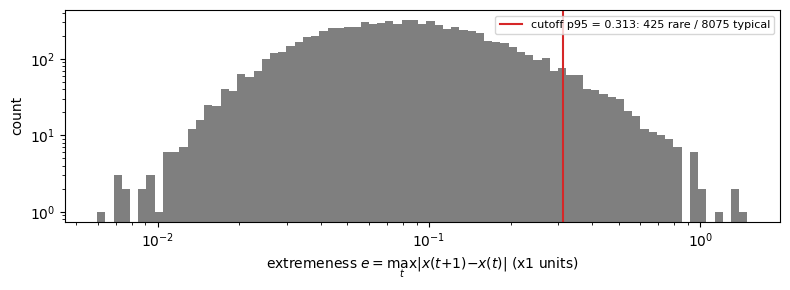

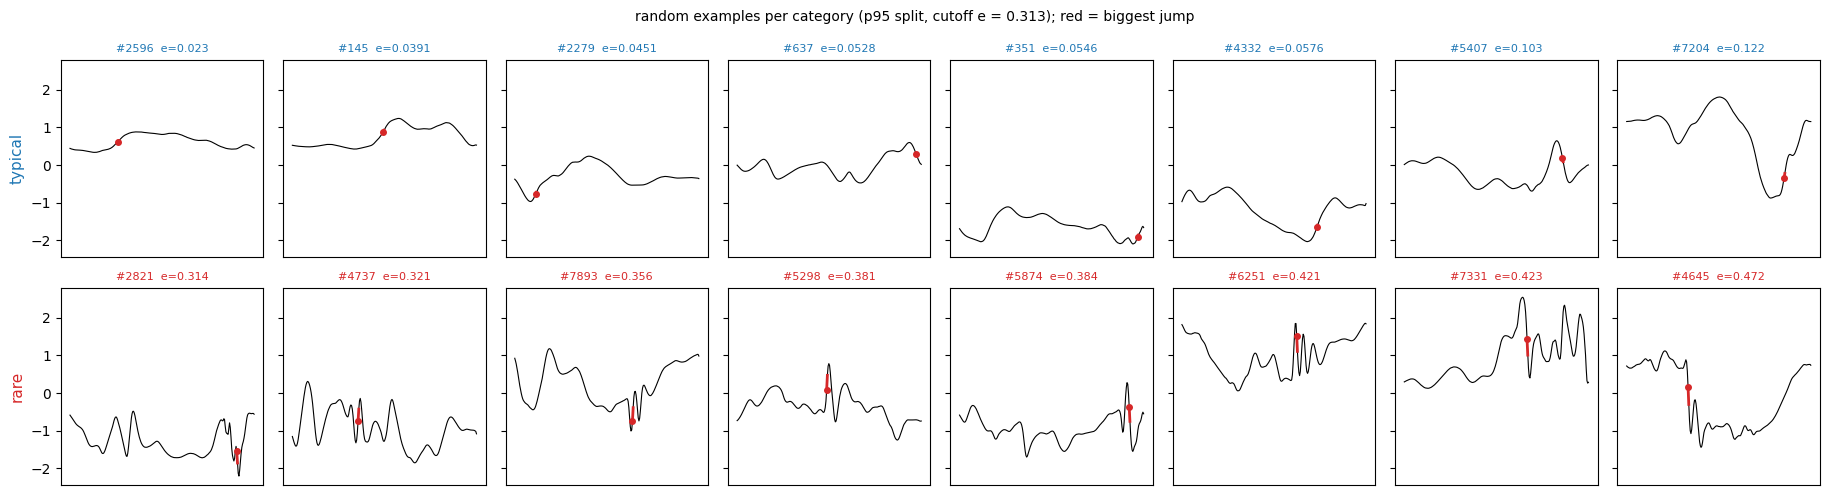

In [23]:
e_split = compute_acceleration(x1).abs().amax(dim=(1, 2)).cpu().numpy()        # (n1,) extremeness e
t_jump = compute_acceleration(x1).abs()[:, 0].argmax(dim=-1).cpu().numpy()    # where the biggest jump is
assert np.array_equal(np.sort(np.flatnonzero(e_split > cutoff_rare)), np.sort(idx_rare))

fig, ax = plt.subplots(figsize=(8, 3))
bins = np.logspace(np.log10(e_split.min()), np.log10(e_split.max()), 80)
ax.hist(e_split, bins=bins, color='tab:gray')
ax.axvline(cutoff_rare, color=category_colors['rare'], lw=1.5,
           label=f'cutoff {P_LABEL} = {cutoff_rare:.3g}: {len(idx_rare)} rare / {len(idx_typical)} typical')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel(r'extremeness $e = \max_t |x(t+1)-x(t)|$ (x1 units)'); ax.set_ylabel('count')
ax.legend(fontsize=8); fig.tight_layout(); plt.show()

rng_ev = np.random.default_rng(EVENT_SEED)
picks = {}
for cat, idx in category_indices.items():
    idx = np.asarray(idx)
    k = min(N_EVENT_EXAMPLES, len(idx))
    if EVENT_PICK == 'extreme':   # rare: largest e; typical: smallest e
        order = np.argsort(e_split[idx])
        chosen = idx[order[::-1][:k]] if cat == 'rare' else idx[order[:k]]
    else:
        chosen = rng_ev.choice(idx, size=k, replace=False)
    picks[cat] = chosen[np.argsort(e_split[chosen])]          # left to right: increasing e

n_col = max(len(v) for v in picks.values())
fig, axes = plt.subplots(2, n_col, figsize=(2.3 * n_col, 5), sharey=True, squeeze=False)
for r, cat in enumerate(['typical', 'rare']):
    for c in range(n_col):
        ax = axes[r][c]
        if c >= len(picks[cat]):
            ax.axis('off'); continue
        i = picks[cat][c]
        sig = x1[i, 0].cpu().numpy()
        ax.plot(sig, lw=0.8, color='black')
        tj = t_jump[i]
        ax.plot([tj, tj + 1], sig[[tj, tj + 1]], color='tab:red', lw=2)
        ax.plot(tj, sig[tj], 'o', color='tab:red', ms=4)
        ax.set_title(f'#{i}  e={e_split[i]:.3g}', fontsize=8, color=category_colors[cat])
        ax.set_xticks([])
    axes[r][0].set_ylabel(cat, color=category_colors[cat], fontsize=11)
fig.suptitle(f"{EVENT_PICK} examples per category ({P_LABEL} split, cutoff e = {cutoff_rare:.3g}); "
             "red = biggest jump", fontsize=10)
fig.tight_layout(); plt.show()

## Per-family energy, split by category

Same `phi_X`/`family_energy`/`total_log_p_unnorm` as the pooled notebook, just indexed by `category_indices` afterward -- the underlying $\theta^\top\varphi(x)$ computation is identical, only the grouping changes.

**Sign convention** (checked in `sde_routines.py`: the sampler ascends $+\nabla_x\,\theta^\top\varphi$): $p_\theta(x)\propto\exp(+\theta^\top\varphi(x))$, so $\theta^\top\varphi(x)=\log p_\theta(x)+\log Z(\theta)$.
Every "log p contribution" below is $\theta_F^\top\varphi_F(x)$ in this convention: higher means more likely.

In [24]:
phi_X = compute_phi_X(potentials_ref, x1).detach().cpu().double().numpy()   # (n1, n_features)
assert phi_X.shape == (n1, n_features), phi_X.shape
phi_by_seed = {k: phi_X if (PHI_SHARED or k == REFERENCE_SEED)
               else compute_phi_X(potentials_by_seed[k], x1).detach().cpu().double().numpy()
               for k in seed_keys}

ranges_with_total = {**family_ranges, 'TOTAL': (0, n_features)}
# C[F]: (n_seeds, n1) -- per-seed, per-signal log p contribution (nats) of family F
C = {F: np.stack([phi_by_seed[k][:, a:b] @ reg_all_np[s, a:b] for s, k in enumerate(seed_keys)])
     for F, (a, b) in ranges_with_total.items()}
# Seed-averaged contribution; with a shared phi_X this is exactly theta_reg_mean . phi(x)
C_bar = {F: C[F].mean(0) for F in C}
family_energy = {F: C_bar[F] for F in family_ranges}
total_log_p_unnorm = C_bar['TOTAL']

comparison = []
for category, idx in category_indices.items():
    for name in ranges_with_total:
        sample_totals = C_bar[name][idx]
        comparison.append({
            'category': category, 'family': name,
            'mean_total': sample_totals.mean(), 'std_total': sample_totals.std(ddof=1),
        })
comparison_df = pd.DataFrame(comparison)
print('seed-averaged theta; std_total = spread across signals')
display(comparison_df.pivot(index='family', columns='category', values=['mean_total', 'std_total']))

seed-averaged theta; std_total = spread across signals


mean_total         std_total         
category                                   rare typical      rare  typical
family                                                                    
L_2_lowpass                                -715    -727  1.02e+03 1.03e+03
L_6                                        78.8    60.2       680      313
Scalar_morlet_gaussianK                   -77.3     107       426      373
Scalar_psi_gaussianK                        544     466       898      864
Scattering_Fourth_Order_Mod2_Imag_Q1        9.2  -0.296       356     30.3
Scattering_Fourth_Order_Mod2_Real_Q1       -267    -148       931      400
TOTAL                                      -427    -242       651      252

reg1e-4: agreement of log p on the 8500 data signals across 5 seeds (corr 1 = identical ranking of signals; July runs: 0.96-0.98)


,chosen by x-seed CV,corr median,corr min,Spearman median,seed spread / signal spread
lam,,,,,
0,,-0.114,-0.472,-0.153,4.19
1e-06,,0.97,0.868,0.998,0.0917
1e-05,,0.857,0.257,0.996,0.0567
0.0001,,0.999,0.892,1,0.0218
0.001,"whole, end0.99, end0.999",0.999,0.996,1,0.00737
0.01,,0.991,0.936,0.999,0.014
0.1,,0.962,0.855,0.998,0.0175
1,,0.0489,-0.419,0.992,0.115
10,,0.827,0.424,0.992,0.0382


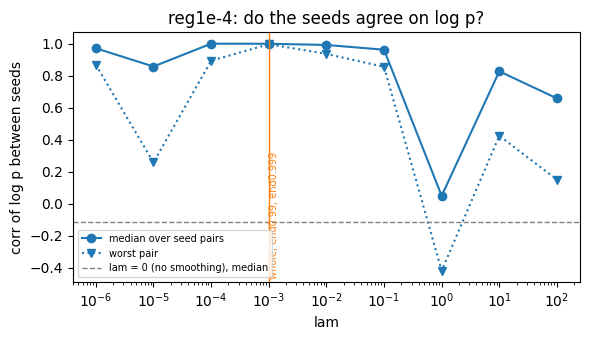

In [25]:
# --- Do the seeds agree on log p, with the time-smoothed Theta at t = 1?  (2026-10-05)
# Paste after the per-family energy cell (uses phi_by_seed, seed_keys, config_by_seed, ARM, root).
# Theta files: phase 1 of lam_selection_criterion/launch_turb_xseed.sh, one per seed and lam
# (Theta_reg[-1] = Theta at the last node, t = 1 - 5e-5). lam = 0 is the per-step theta with the
# run's ridge (no time smoothing). Run once per arm: set ARM in the settings cell and rerun.
from collections import defaultdict
from scipy import stats

SWEEP_XSEED = Path(os.environ['SCRATCH']) / 'MGD-for-Maximum-Entropy-Generation/turbulence/theta_reg_lamsweep_xseed'
RIDGE_ARM = {'reg1e-4': 1e-4, 'reg1e-2': 1e-2}[ARM]
LAMS_X = [0, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1, 10, 100]
xs_file = root.parent / 'lam_selection_criterion' / 'results' / 'turb_xseed' / f'xseed_noL6psi_noSm30_{ARM}.pt'
chosen = defaultdict(list)                      # lam -> windows of the cross-seed CV that chose it
if xs_file.exists():
    for w, lam in torch.load(xs_file, map_location='cpu', weights_only=False)['selected'].items():
        chosen[lam].append(w)
else:
    print(f'(no {xs_file.name} yet: phase 2 not finished, the "chosen" column stays empty)')

rows, logp_by_lam = [], {}
iu = np.triu_indices(len(seed_keys), 1)
for lam in LAMS_X:
    files = [SWEEP_XSEED / config_by_seed[k] / f'lam{lam:g}_ridge{RIDGE_ARM:g}_moment_mask.pt' for k in seed_keys]
    if not all(f.exists() for f in files):
        print(f'lam={lam:g}: {sum(not f.exists() for f in files)} seed file(s) missing (phase 1 still running?), skipped')
        continue
    lp = []
    for k, f in zip(seed_keys, files):
        th = torch.load(f, map_location='cpu', weights_only=False)['Theta_reg'][-1].double().numpy()
        assert th.shape[0] == phi_by_seed[k].shape[1], (th.shape, phi_by_seed[k].shape)
        lp.append(phi_by_seed[k] @ th)          # log p (unnormalised, code sign) of every data signal
    lp = np.stack(lp)                           # (n_seeds, n1)
    logp_by_lam[lam] = lp
    c = np.corrcoef(lp)[iu]
    rho = stats.spearmanr(lp, axis=1).correlation
    rho = np.atleast_2d(rho)[iu] if np.ndim(rho) else np.array([rho])
    rows.append({'lam': lam, 'chosen by x-seed CV': ', '.join(chosen.get(lam, [])),
                 'corr median': np.median(c), 'corr min': c.min(), 'Spearman median': np.median(rho),
                 # how much a signal's log p moves between seeds, relative to how much it varies across signals
                 'seed spread / signal spread': lp.std(0, ddof=1).mean() / lp.mean(0).std(ddof=1)})
agree = pd.DataFrame(rows).set_index('lam')
print(f'{ARM}: agreement of log p on the {lp.shape[1]} data signals across {len(seed_keys)} seeds '
      f'(corr 1 = identical ranking of signals; July runs: 0.96-0.98)')
display(agree)

if len(agree):
    fig, ax = plt.subplots(figsize=(6, 3.5))
    pos = agree.index[agree.index > 0]
    ax.plot(pos, agree.loc[pos, 'corr median'], 'o-', color='tab:blue', label='median over seed pairs')
    ax.plot(pos, agree.loc[pos, 'corr min'], 'v:', color='tab:blue', label='worst pair')
    if 0 in agree.index:
        ax.axhline(agree.loc[0, 'corr median'], color='gray', ls='--', lw=1, label='lam = 0 (no smoothing), median')
    for lam, ws in chosen.items():
        if lam > 0:
            ax.axvline(lam, color='tab:orange', lw=1)
            ax.text(lam, ax.get_ylim()[0], ' ' + ', '.join(ws), rotation=90, va='bottom', fontsize=7, color='tab:orange')
    ax.set_xscale('log'); ax.set_xlabel('lam'); ax.set_ylabel('corr of log p between seeds')
    ax.set_title(f'{ARM}: do the seeds agree on log p?'); ax.legend(fontsize=7)
    fig.tight_layout(); plt.show()

lam = 0.001: the 20 signals with the largest seed spread of log p (20/20 rare, p95; 5.0% of all signals are rare)


,log p seed spread,log p mean,extremeness e,e percentile,rare
signal,,,,,
4578,381,-1.25e+03,1.35,100,True
4572,156,-1.01e+03,1.34,100,True
1487,144,-564,0.97,99.9,True
315,108,-456,0.916,99.9,True
4592,88.4,-821,1.49,100,True
4287,68.5,-827,0.692,99.6,True
995,60.4,-640,0.842,99.8,True
5321,58,-622,0.756,99.7,True
5945,44.9,-696,0.92,99.9,True


Spearman(seed spread, extremeness) over all signals: 0.535  (> 0: the seeds disagree more on extreme signals)
median seed spread: rare 2.3 | typical 0.639
  without the   0 most-disagreed signals: corr median 0.999, worst pair 0.996
  without the   5 most-disagreed signals: corr median 1.000, worst pair 1.000
  without the  20 most-disagreed signals: corr median 1.000, worst pair 1.000
  without the 100 most-disagreed signals: corr median 1.000, worst pair 1.000


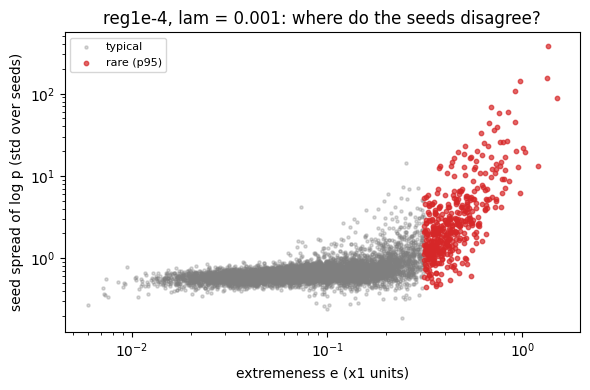

In [26]:
# --- Which signals do the seeds disagree on?  (2026-10-05)
# Paste after the agreement cell (uses logp_by_lam from it, and e_split, idx_rare, P_LABEL from the
# rare/typical cells above). For one lam: per signal, the spread of its log p across the 5 seeds, against
# how extreme the signal is (e = max |x(t+1) - x(t)|, the quantity the rare/typical split uses).
LAM_CHECK = 1e-3          # the lam where Pearson dipped while Spearman stayed ~1; then try the chosen lam
TOP = 20                   # signals listed

lp = logp_by_lam[LAM_CHECK]                       # (n_seeds, n1)
sd = lp.std(0, ddof=1)                            # seed-to-seed spread of each signal's log p
mu = lp.mean(0)
is_rare = np.zeros(lp.shape[1], bool); is_rare[np.asarray(idx_rare)] = True
e_pct = stats.rankdata(e_split) / len(e_split) * 100          # extremeness percentile of each signal

order = np.argsort(sd)[::-1]
top = pd.DataFrame({'signal': order[:TOP], 'log p seed spread': sd[order[:TOP]], 'log p mean': mu[order[:TOP]],
                    'extremeness e': e_split[order[:TOP]], 'e percentile': e_pct[order[:TOP]],
                    'rare': is_rare[order[:TOP]]}).set_index('signal')
print(f'lam = {LAM_CHECK:g}: the {TOP} signals with the largest seed spread of log p '
      f'({int(top["rare"].sum())}/{TOP} rare, {P_LABEL}; {is_rare.mean() * 100:.1f}% of all signals are rare)')
display(top)

rho = stats.spearmanr(sd, e_split).correlation
print(f'Spearman(seed spread, extremeness) over all signals: {rho:.3f}  (> 0: the seeds disagree more on extreme signals)')
print(f'median seed spread: rare {np.median(sd[is_rare]):.3g} | typical {np.median(sd[~is_rare]):.3g}')

# does a handful of signals explain the Pearson dip? drop the K most-disagreed signals and recompute
iu5 = np.triu_indices(lp.shape[0], 1)
for K in (0, 5, 20, 100):
    keep = np.ones(lp.shape[1], bool); keep[order[:K]] = False
    c = np.corrcoef(lp[:, keep])[iu5]
    print(f'  without the {K:3d} most-disagreed signals: corr median {np.median(c):.3f}, worst pair {c.min():.3f}')

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(e_split[~is_rare], sd[~is_rare], s=5, alpha=0.3, color='tab:gray', label='typical')
ax.scatter(e_split[is_rare], sd[is_rare], s=10, alpha=0.7, color='tab:red', label=f'rare ({P_LABEL})')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('extremeness e (x1 units)'); ax.set_ylabel('seed spread of log p (std over seeds)')
ax.set_title(f'{ARM}, lam = {LAM_CHECK:g}: where do the seeds disagree?'); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

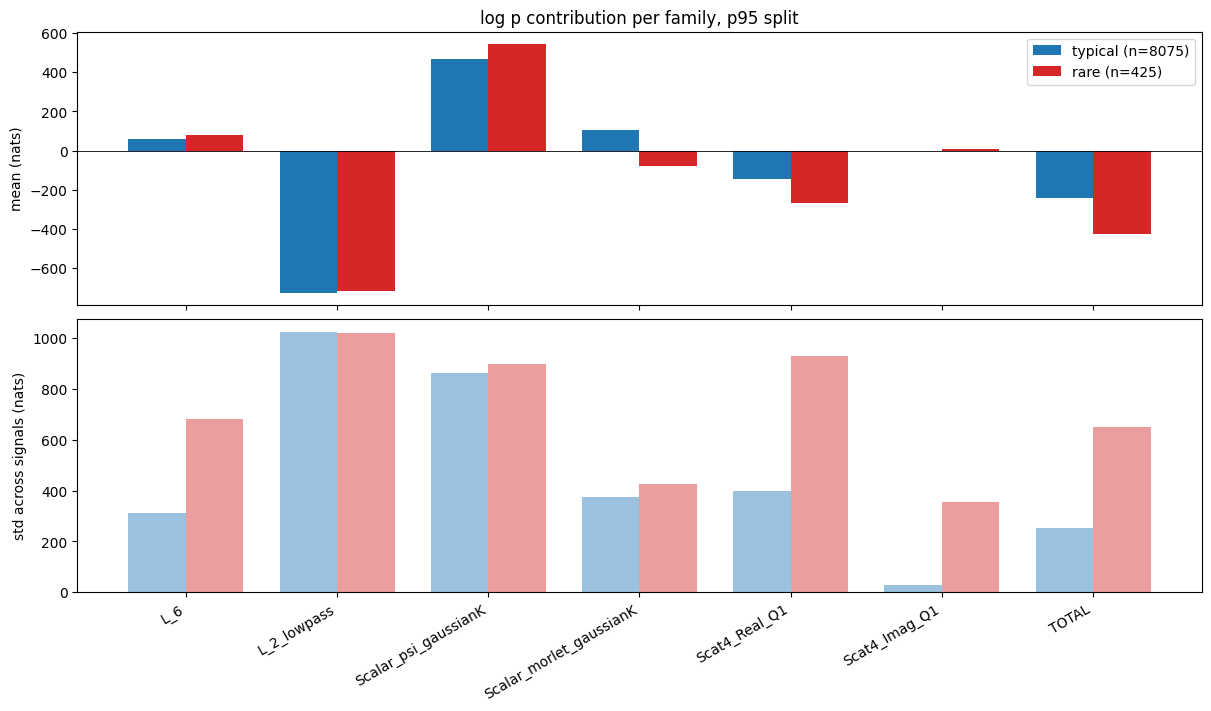

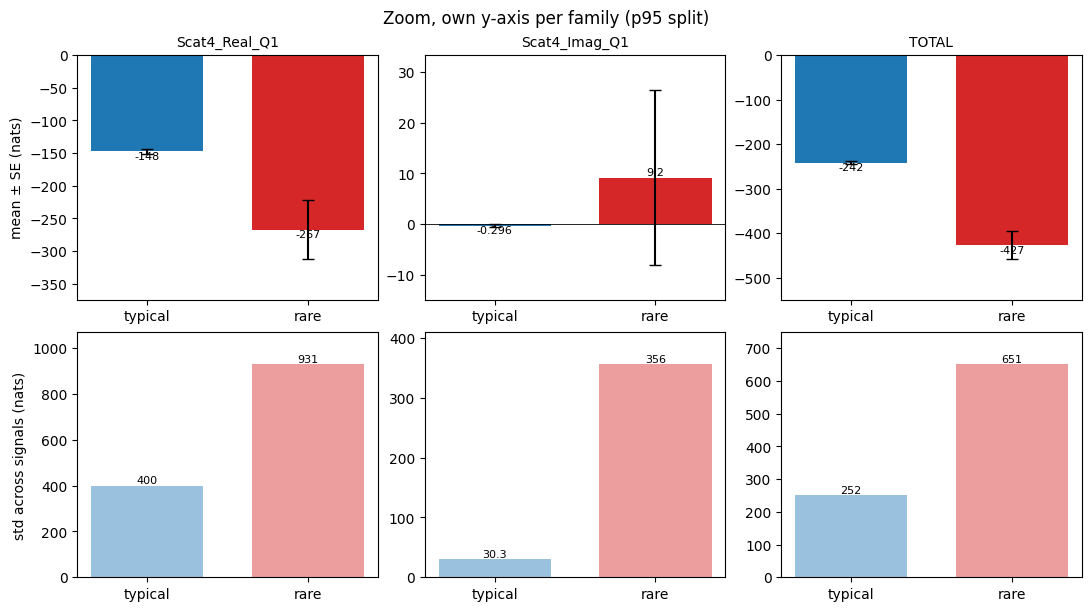

In [27]:
from matplotlib.colors import to_rgba

short = lambda F: F.replace('Scattering_Fourth_Order_Mod2_', 'Scat4_')
categories = list(category_indices.keys())
family_names = list(ranges_with_total.keys())   # all families + TOTAL
cat_stats = comparison_df.set_index(['category', 'family'])   # not called `stats`: that name is scipy.stats below
means = {c: cat_stats.loc[c].loc[family_names, 'mean_total'].to_numpy() for c in categories}
stds = {c: cat_stats.loc[c].loc[family_names, 'std_total'].to_numpy() for c in categories}
n_cat = {c: len(category_indices[c]) for c in categories}
width = 0.38
offsets = {c: (i - (len(categories) - 1) / 2) * width for i, c in enumerate(categories)}

# Full range: all families on one axis (the L_6 / Scalar families set the scale)
x = np.arange(len(family_names))
fig, (ax_mean, ax_std) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, constrained_layout=True)
for c in categories:
    ax_mean.bar(x + offsets[c], means[c], width, color=category_colors[c], label=f'{c} (n={n_cat[c]})')
    ax_std.bar(x + offsets[c], stds[c], width, color=to_rgba(category_colors[c], 0.45), label=c)
ax_mean.axhline(0, color='k', lw=0.6)
ax_mean.set_ylabel('mean (nats)'); ax_std.set_ylabel('std across signals (nats)')
ax_std.set_xticks(x); ax_std.set_xticklabels([short(F) for F in family_names], rotation=30, ha='right')
ax_mean.set_title(f'log p contribution per family, {P_LABEL} split'); ax_mean.legend()
plt.show()

# Zoom: one panel per family in ZOOM_FAMILIES, each with its OWN y-axis (otherwise Scat4_Real's
# scale flattens Scat4_Imag). Error bars on the mean = standard error (std / sqrt(n)).
fig, axes = plt.subplots(2, len(ZOOM_FAMILIES), figsize=(3.6 * len(ZOOM_FAMILIES), 6),
                         squeeze=False, constrained_layout=True)
for j, F in enumerate(ZOOM_FAMILIES):
    k = family_names.index(F)
    ax_m, ax_s = axes[0][j], axes[1][j]
    for i, c in enumerate(categories):
        m, s = means[c][k], stds[c][k]
        ax_m.bar(i, m, 0.7, yerr=s / np.sqrt(n_cat[c]), capsize=4, color=category_colors[c])
        ax_m.annotate(f'{m:.3g}', (i, m), ha='center', va='bottom' if m >= 0 else 'top', fontsize=8)
        ax_s.bar(i, s, 0.7, color=to_rgba(category_colors[c], 0.45))
        ax_s.annotate(f'{s:.3g}', (i, s), ha='center', va='bottom', fontsize=8)
    ax_m.axhline(0, color='k', lw=0.6)
    ax_m.margins(y=0.2); ax_s.margins(y=0.15)
    ax_m.set_title(short(F), fontsize=10)
    for ax in (ax_m, ax_s):
        ax.set_xticks(range(len(categories))); ax.set_xticklabels(categories)
axes[0][0].set_ylabel('mean ± SE (nats)'); axes[1][0].set_ylabel('std across signals (nats)')
fig.suptitle(f'Zoom, own y-axis per family ({P_LABEL} split)')
plt.show()

## log p, typical vs rare

$\theta^\top\varphi(x)$ = $\log p_\theta(x)$ up to the additive constant $-\log Z(\theta)$ -- the SAME constant for both categories (same $\theta$), so shape and the gap between them are exact; only the absolute axis position is unknown.

typical: gumbel_r: loc=-361, scale=481.8, loglik=-5.996e+04, KS D=0.305 | gumbel_l: loc=-55.65, scale=985.3, loglik=-6.526e+04, KS D=0.403  -> best: gumbel_r
rare: gumbel_r: loc=-781.1, scale=1085, loglik=-3534, KS D=0.252 | gumbel_l: loc=-95.79, scale=883.1, loglik=-3468, KS D=0.216  -> best: gumbel_l


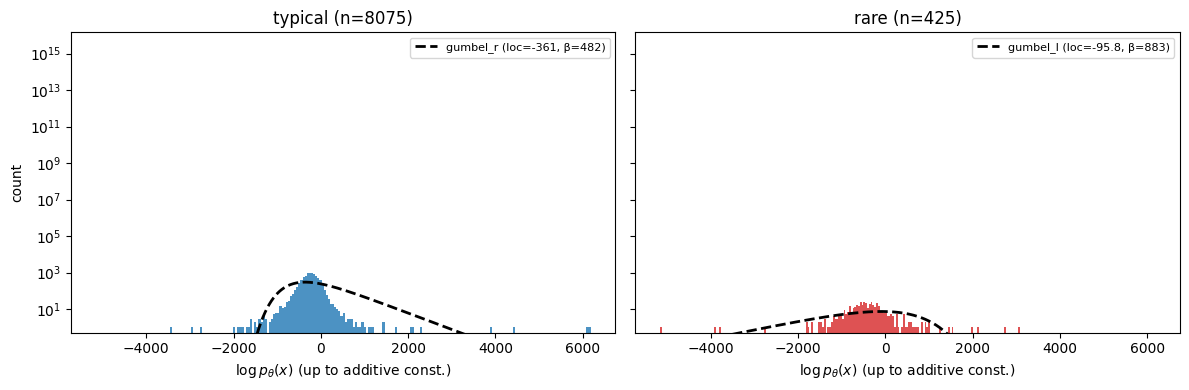

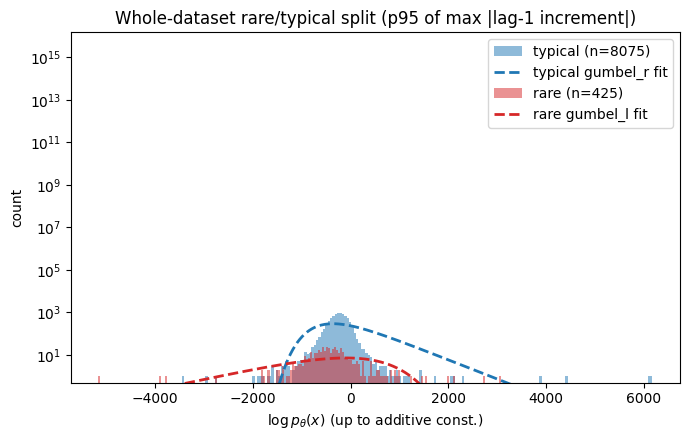

mean log p_theta, up to the same additive constant: typical = -241.6, rare = -427.3  ->  rare < typical: True


In [28]:
from scipy import stats

def _to_np(x):
    return x.detach().cpu().numpy().astype(float) if hasattr(x, 'detach') else np.asarray(x, dtype=float)

logp_by_category = {category: _to_np(total_log_p_unnorm[idx]) for category, idx in category_indices.items()}

# --- Gumbel fit per category: try both orientations, keep the better one by log-likelihood ---
gumbel_fits = {}
for category, x in logp_by_category.items():
    candidates = {}
    for name, dist in (('gumbel_r', stats.gumbel_r), ('gumbel_l', stats.gumbel_l)):
        loc, scale = dist.fit(x)
        candidates[name] = dict(dist=dist, loc=loc, scale=scale,
                                loglik=dist.logpdf(x, loc, scale).sum(),
                                ks=stats.kstest(x, dist.cdf, args=(loc, scale)).statistic)
    best = max(candidates, key=lambda k: candidates[k]['loglik'])
    gumbel_fits[category] = {**candidates[best], 'kind': best}
    print(f"{category}: " + " | ".join(
        f"{k}: loc={c['loc']:.4g}, scale={c['scale']:.4g}, loglik={c['loglik']:.4g}, KS D={c['ks']:.3g}"
        for k, c in candidates.items()) + f"  -> best: {best}")

def _overlay_gumbel(ax, x, edges, fit, color, label=None):
    grid = np.linspace(edges[0], edges[-1], 400)
    bin_width = edges[1] - edges[0]
    ax.plot(grid, fit['dist'].pdf(grid, fit['loc'], fit['scale']) * len(x) * bin_width,
            color=color, lw=2, ls='--', label=label)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
for ax, (category, logp) in zip(axes, logp_by_category.items()):
    color = category_colors.get(category, 'tab:gray')
    _, edges, _ = ax.hist(logp, bins=200, color=color, alpha=0.8)
    fit = gumbel_fits[category]
    _overlay_gumbel(ax, logp, edges, fit, 'k',
                    label=f"{fit['kind']} (loc={fit['loc']:.3g}, β={fit['scale']:.3g})")
    ax.set_title(f'{category} (n={len(logp)})')
    ax.set_xlabel(r'$\log p_\theta(x)$ (up to additive const.)')
    ax.set_yscale('log')
    ax.set_ylim(bottom=0.5)   # keep the pdf's far tail from stretching the log axis
    ax.legend(fontsize=8)
axes[0].set_ylabel('count')
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
for category, logp in logp_by_category.items():
    color = category_colors.get(category, 'tab:gray')
    _, edges, _ = ax.hist(logp, bins=200, color=color, alpha=0.5, label=f'{category} (n={len(logp)})')
    _overlay_gumbel(ax, logp, edges, gumbel_fits[category], color,
                    label=f"{category} {gumbel_fits[category]['kind']} fit")
ax.set_xlabel(r'$\log p_\theta(x)$ (up to additive const.)')
ax.set_ylabel('count')
ax.set_yscale('log')
ax.set_ylim(bottom=0.5)
ax.legend()
ax.set_title(f'Whole-dataset rare/typical split ({P_LABEL} of max |lag-1 increment|)')
fig.tight_layout()
plt.show()

mean_logp = {category: logp.mean() for category, logp in logp_by_category.items()}
print("mean log p_theta, up to the same additive constant: "
      + ", ".join(f"{category} = {m:.4g}" for category, m in mean_logp.items())
      + f"  ->  rare < typical: {mean_logp['rare'] < mean_logp['typical']}")

The printed line above says whether rare events sit at lower $\log p_\theta$ (seed-averaged θ) than typical ones for these runs. The gap between the two means is exact, because $\log Z(\theta)$ is the same for both.

In [29]:
# --- Physical sign check of log p (2026-10-05)
# Paste after the per-family energy cell (uses compute_phi_X, potentials_ref, reg_all_np, x1, total_log_p_unnorm).
# log p must DROP when (1) white noise is added to the data and (2) the data amplitude grows (alpha > 1), and
# RISE when the amplitude shrinks (alpha < 1): the density is highest for small, quiet signals (the data sit where
# the probability MASS is, not at the peak of the density -- as Guth's constant image is the most probable);
# (3) white noise with the data variance must sit far LEFT of the data histogram, a constant signal to the right.
# A flipped sign would show the opposite on all three.
N_SIG = 300                                        # data signals used (a random subset)
rng_c = np.random.default_rng(1)
sub = torch.as_tensor(rng_c.choice(x1.shape[0], N_SIG, replace=False))
xs = x1[sub].to(x1.device)
theta_bar = reg_all_np.mean(0)                     # seed-averaged theta (as total_log_p_unnorm)
logp = lambda x: compute_phi_X(potentials_ref, x).double().numpy() @ theta_bar
lp0 = logp(xs)                                     # log p of the unperturbed signals
sd_data = float(x1.std())

print('(1) white noise added (std = level x data std): median change of log p over the signals')
noise = torch.randn_like(xs)
for level in (0.01, 0.03, 0.1, 0.3, 1.0):
    d = logp(xs + level * sd_data * noise) - lp0
    print(f'   level {level:5.2f}: median {np.median(d):12.4g}   fraction of signals where log p dropped: {np.mean(d < 0):.2f}')

print('(2) amplitude x alpha: median log p(alpha x) - log p(x)  (should DECREASE with alpha: > 0 below 1, < 0 above)')
alphas = [0.25, 0.5, 0.8, 0.9, 1.0, 1.1, 1.25, 2.0, 4.0]
med = [np.median(logp(a * xs) - lp0) for a in alphas]
for a, m in zip(alphas, med):
    print(f'   alpha {a:4.2f}: {m:12.4g}')
print(f'   -> decreasing in alpha: {all(a > b for a, b in zip(med, med[1:]))}')

print("(3) Guth's arrows, against the data's log p (all n1 signals)")
lp_all = np.asarray(total_log_p_unnorm, dtype=float)
wn = logp(torch.randn_like(xs[:50]) * sd_data)
cst = logp(torch.zeros_like(xs[:1]))
print(f'   data log p: min {lp_all.min():.4g}, median {np.median(lp_all):.4g}, max {lp_all.max():.4g}')
print(f'   white noise (data std): median {np.median(wn):.4g}  -> below every data signal: {wn.max() < lp_all.min()}')
print(f'   constant zero signal: {cst[0]:.4g}  -> above the data median: {cst[0] > np.median(lp_all)}')

(1) white noise added (std = level x data std): median change of log p over the signals
   level  0.01: median       -758.8   fraction of signals where log p dropped: 1.00
   level  0.03: median        -1263   fraction of signals where log p dropped: 1.00
   level  0.10: median        -1252   fraction of signals where log p dropped: 0.83
   level  0.30: median    1.025e+05   fraction of signals where log p dropped: 0.01
   level  1.00: median    2.541e+07   fraction of signals where log p dropped: 0.00
(2) amplitude x alpha: median log p(alpha x) - log p(x)  (should DECREASE with alpha: > 0 below 1, < 0 above)
   alpha 0.25:        180.5
   alpha 0.50:        68.56
   alpha 0.80:        29.57
   alpha 0.90:        10.86
   alpha 1.00:            0
   alpha 1.10:        -9.16
   alpha 1.25:       -12.68
   alpha 2.00:       -48.94
   alpha 4.00:         5920
   -> decreasing in alpha: False
(3) Guth's arrows, against the data's log p (all n1 signals)
   data log p: min -5165, median -24

In [30]:
# --- Which family makes log p RISE at noise level ~0.3?  (2026-10-06)
phi0 = compute_phi_X(potentials_ref, xs).double().numpy()
rows = []
for level in (0.1, 0.15, 0.2, 0.3, 0.5, 0.7, 1.0):
    dphi = compute_phi_X(potentials_ref, xs + level * sd_data * noise).double().numpy() - phi0
    rows.append({'level': level, **{F: np.median(dphi[:, a:b] @ theta_bar[a:b]) for F, (a, b) in family_ranges.items()},
                 'TOTAL': np.median(dphi @ theta_bar)})
print('median change of each family\'s log p contribution (nats); medians do not add up to TOTAL exactly')
display(pd.DataFrame(rows).set_index('level'))

median change of each family's log p contribution (nats); medians do not add up to TOTAL exactly


,L_6,L_2_lowpass,Scalar_psi_gaussianK,Scalar_morlet_gaussianK,Scattering_Fourth_Order_Mod2_Real_Q1,Scattering_Fourth_Order_Mod2_Imag_Q1,TOTAL
level,,,,,,,
0.1,13.8,0.115,-1.41e+03,-425,631,1.31,-1.25e+03
0.15,150,0.172,-1.7e+03,-464,4.81e+03,-3.99,2.68e+03
0.2,832,0.228,-1.95e+03,-501,1.7e+04,19.3,1.51e+04
0.3,9.34e+03,0.337,-2.35e+03,-594,9.48e+04,185,1.03e+05
0.5,2.01e+05,0.544,-2.88e+03,-873,7.64e+05,70.5,9.77e+05
0.7,1.51e+06,0.542,-3.19e+03,-1.17e+03,2.98e+06,1.43e+03,4.46e+06
1,1.28e+07,0.697,-3.44e+03,-1.57e+03,1.25e+07,-7.13e+03,2.54e+07


## Florentin's plot

Data signals ordered by $\log p_\theta$ (up to the constant), from least to most likely. The $\log p$ distribution has heavy outlier tails, so examples spaced **linearly** in $\log p$ fall mostly in empty tail regions. There the nearest signal is the same one several times, which gave duplicates. The default (`EXAMPLE_SPACING = 'quantile'`) spaces them equally in **rank** instead: panel $k$ is the signal at the $k$-th quantile within `EXAMPLE_RANGE`, so every panel is a distinct signal. The strip on top shows where the chosen examples sit in the $\log p$ histogram. Titles are red for rare and blue for typical signals.

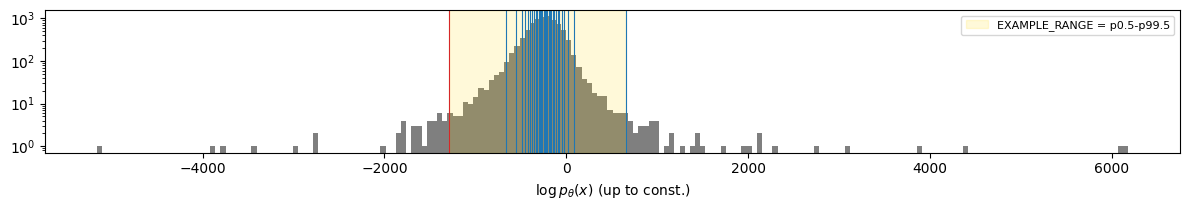

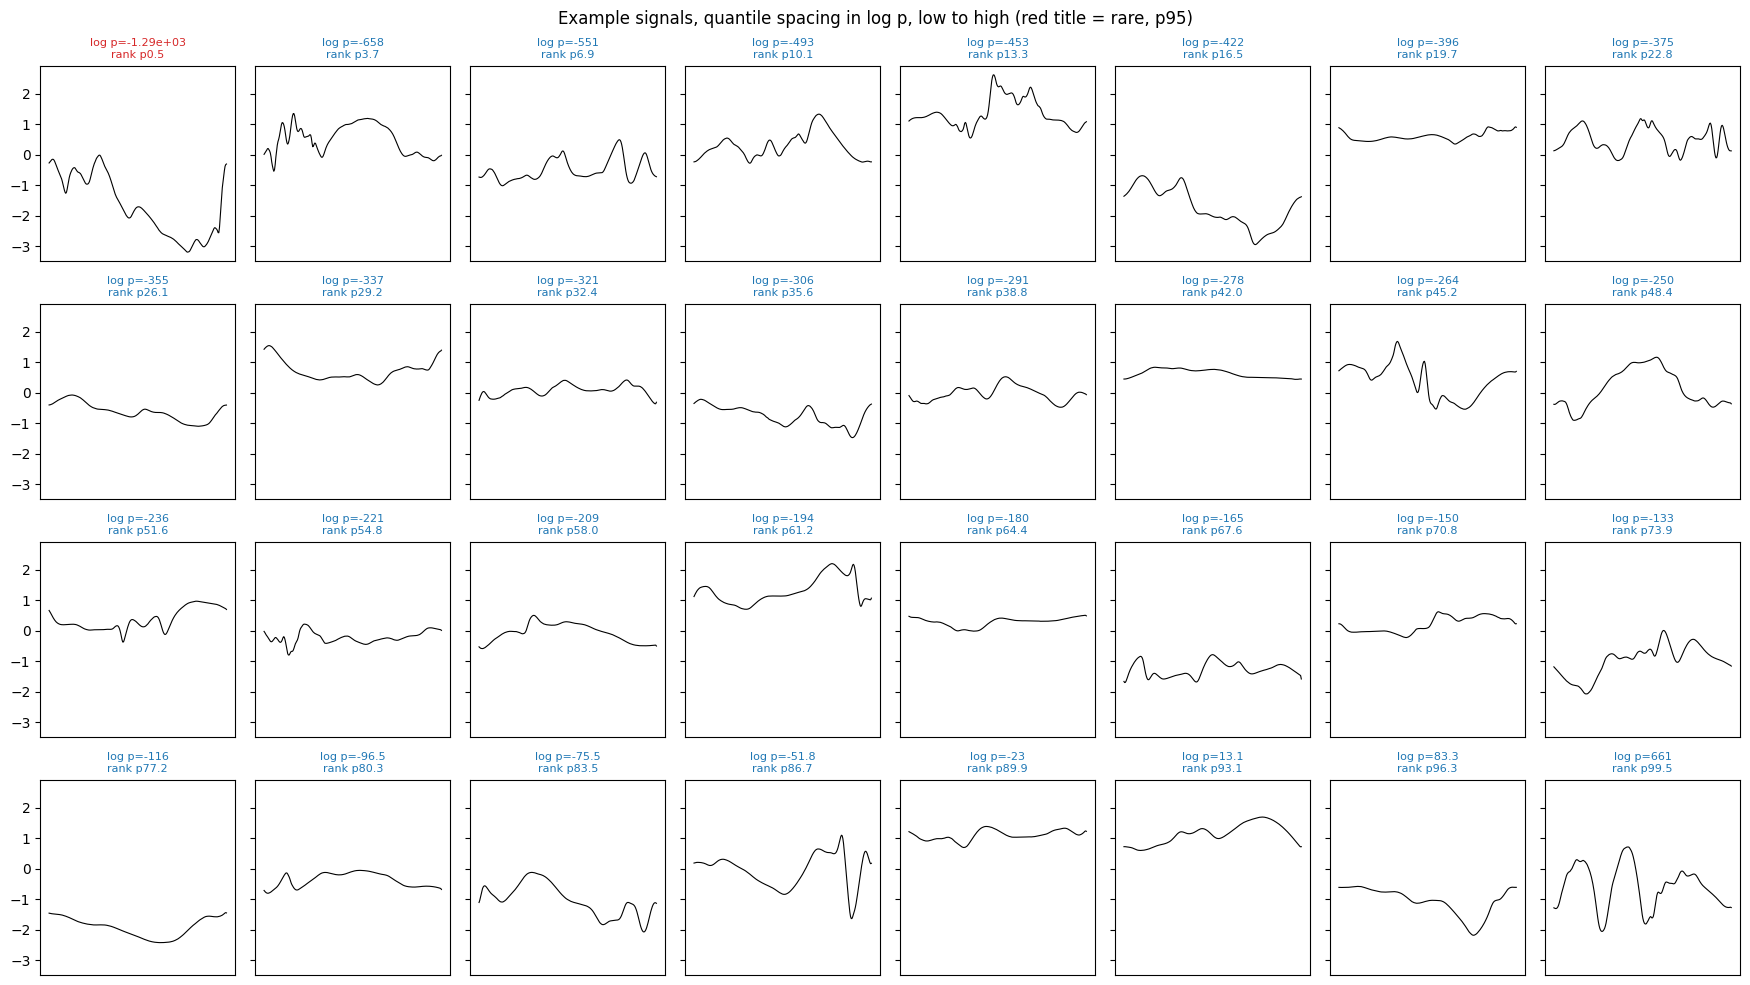

In [31]:
logp_all = np.asarray(total_log_p_unnorm, dtype=float)
lo_q, hi_q = EXAMPLE_RANGE
order = np.argsort(logp_all)                                   # signal indices, low to high log p
rank_lo, rank_hi = (int(round(q / 100 * (n1 - 1))) for q in (lo_q, hi_q))
if EXAMPLE_SPACING == 'quantile':
    ranks = np.unique(np.linspace(rank_lo, rank_hi, N_EXAMPLES).round().astype(int))
    example_idx = order[ranks]
elif EXAMPLE_SPACING == 'linear':
    targets = np.linspace(logp_all[order[rank_lo]], logp_all[order[rank_hi]], N_EXAMPLES)
    nearest = [int(np.argmin(np.abs(logp_all - t))) for t in targets]
    example_idx = np.array(list(dict.fromkeys(nearest)))      # drop repeats, keep order
    if len(example_idx) < N_EXAMPLES:
        print(f"linear spacing: {N_EXAMPLES - len(example_idx)} targets hit an already-shown signal, dropped")
else:
    raise ValueError(f"EXAMPLE_SPACING must be 'quantile' or 'linear', got {EXAMPLE_SPACING!r}")
rank_of = np.empty(n1, dtype=int); rank_of[order] = np.arange(n1)

# Where the examples sit in the log p distribution
fig, ax = plt.subplots(figsize=(12, 2.2))
ax.hist(logp_all, bins=200, color='tab:gray')
for i in example_idx:
    ax.axvline(logp_all[i], color=category_colors['rare' if i in rare_set else 'typical'], lw=0.8)
ax.axvspan(logp_all[order[rank_lo]], logp_all[order[rank_hi]], color='gold', alpha=0.15,
           label=f'EXAMPLE_RANGE = p{lo_q:g}-p{hi_q:g}')
ax.set_yscale('log'); ax.set_xlabel(r'$\log p_\theta(x)$ (up to const.)'); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

n_cols = 8
n_rows = math.ceil(len(example_idx) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.2 * n_cols, 2.5 * n_rows), sharey=EXAMPLE_SHAREY, squeeze=False)
for k, i in enumerate(example_idx):
    ax = axes[k // n_cols][k % n_cols]
    ax.plot(x1[i, 0].cpu().numpy(), lw=0.8, color='black')
    ax.set_title(f'log p={logp_all[i]:.3g}\nrank p{100 * rank_of[i] / (n1 - 1):.1f}', fontsize=8,
                 color=category_colors['rare' if i in rare_set else 'typical'])
    ax.set_xticks([])
for j in range(len(example_idx), n_rows * n_cols):
    axes[j // n_cols][j % n_cols].axis('off')
fig.suptitle(f'Example signals, {EXAMPLE_SPACING} spacing in log p, low to high (red title = rare, {P_LABEL})')
fig.tight_layout(); plt.show()

## 1. Per-seed family contributions with error bars

For each seed $s$, `C[F][s, i]` $=\theta_{s,F}^\top\varphi_F(x_i)$ (log p contribution, nats), and `D[s, F]` = mean of `C[F][s]` over rare minus mean over typical. The table gives the mean/std of `D` across seeds, plus a bootstrap SE over the `len(idx_rare)` rare signals (resampled with the seed-averaged `C`; typical held fixed). The counts are printed below.

sum(family D) - TOTAL D = 1.961e-12  (should be ~0)
D over 5 seeds; bootstrap: 1000 resamples of the 425 rare signals (typical, n=8075, held fixed)


,family,mean_D,std_D_across_seeds,bootstrap_SE_rare
0,L_6,18.6,106,32.8
1,L_2_lowpass,12.3,29.3,47.9
2,Scalar_psi_gaussianK,77.5,725,42.1
3,Scalar_morlet_gaussianK,-184,1.48e+03,20.9
4,Scattering_Fourth_Order_Mod2_Real_Q1,-120,585,43.1
5,Scattering_Fourth_Order_Mod2_Imag_Q1,9.49,106,17.2
6,TOTAL,-186,372,30.2


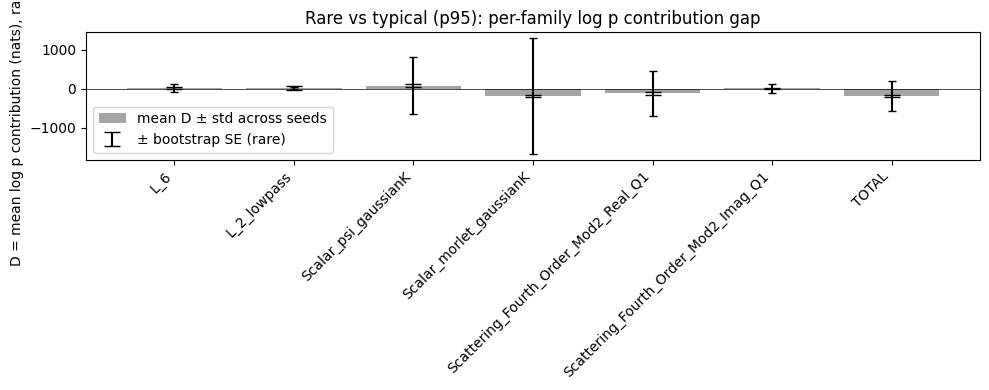

In [32]:
family_names_all = list(ranges_with_total.keys())  # all families + TOTAL
# C[F] (n_seeds, n1) and C_bar[F] (n1,) are built in the per-family energy cell above

D = np.stack([C[F][:, idx_rare].mean(axis=1) - C[F][:, idx_typical].mean(axis=1)
              for F in family_names_all], axis=1)  # (n_seeds, n_families+1)
D_mean = D.mean(axis=0)
D_std = D.std(axis=0, ddof=1) if n_seeds > 1 else np.full(D.shape[1], np.nan)

# sanity check: C[TOTAL] = sum_F C[F] exactly (linear), so D[TOTAL] should equal sum_F D[F]
total_i = family_names_all.index('TOTAL')
family_sum = sum(D_mean[i] for i, F in enumerate(family_names_all) if F != 'TOTAL')
print(f"sum(family D) - TOTAL D = {family_sum - D_mean[total_i]:.3e}  (should be ~0)")

# Bootstrap SE over the rare signals only (typical held fixed), using the
# seed-averaged C_bar.
rng = np.random.default_rng(BOOT_SEED)
n_boot = N_BOOT
idx_rare_arr = np.array(idx_rare)
typical_mean = {F: C_bar[F][idx_typical].mean() for F in family_names_all}
boot_D = np.empty((n_boot, len(family_names_all)))
for b in range(n_boot):
    resample = rng.choice(idx_rare_arr, size=len(idx_rare_arr), replace=True)
    boot_D[b] = [C_bar[F][resample].mean() - typical_mean[F] for F in family_names_all]
boot_se = boot_D.std(axis=0, ddof=1)
print(f"D over {n_seeds} seeds; bootstrap: {n_boot} resamples of the {len(idx_rare)} rare signals "
      f"(typical, n={len(idx_typical)}, held fixed)")

table1 = pd.DataFrame({'family': family_names_all, 'mean_D': D_mean,
                        'std_D_across_seeds': D_std, 'bootstrap_SE_rare': boot_se})
display(table1)

fig, ax = plt.subplots(figsize=(10, 4))
xpos = np.arange(len(family_names_all))
ax.bar(xpos, D_mean, yerr=D_std, capsize=3, color='tab:gray', alpha=0.7,
       label='mean D ± std across seeds')
ax.errorbar(xpos, D_mean, yerr=boot_se, fmt='none', ecolor='black', capsize=6, lw=1.5,
            label='± bootstrap SE (rare)')
ax.axhline(0, color='black', lw=0.5)
ax.set_xticks(xpos); ax.set_xticklabels(family_names_all, rotation=45, ha='right')
ax.set_ylabel('D = mean log p contribution (nats), rare - typical')
ax.set_title(f'Rare vs typical ({P_LABEL}): per-family log p contribution gap')
ax.legend()
fig.tight_layout()
plt.show()

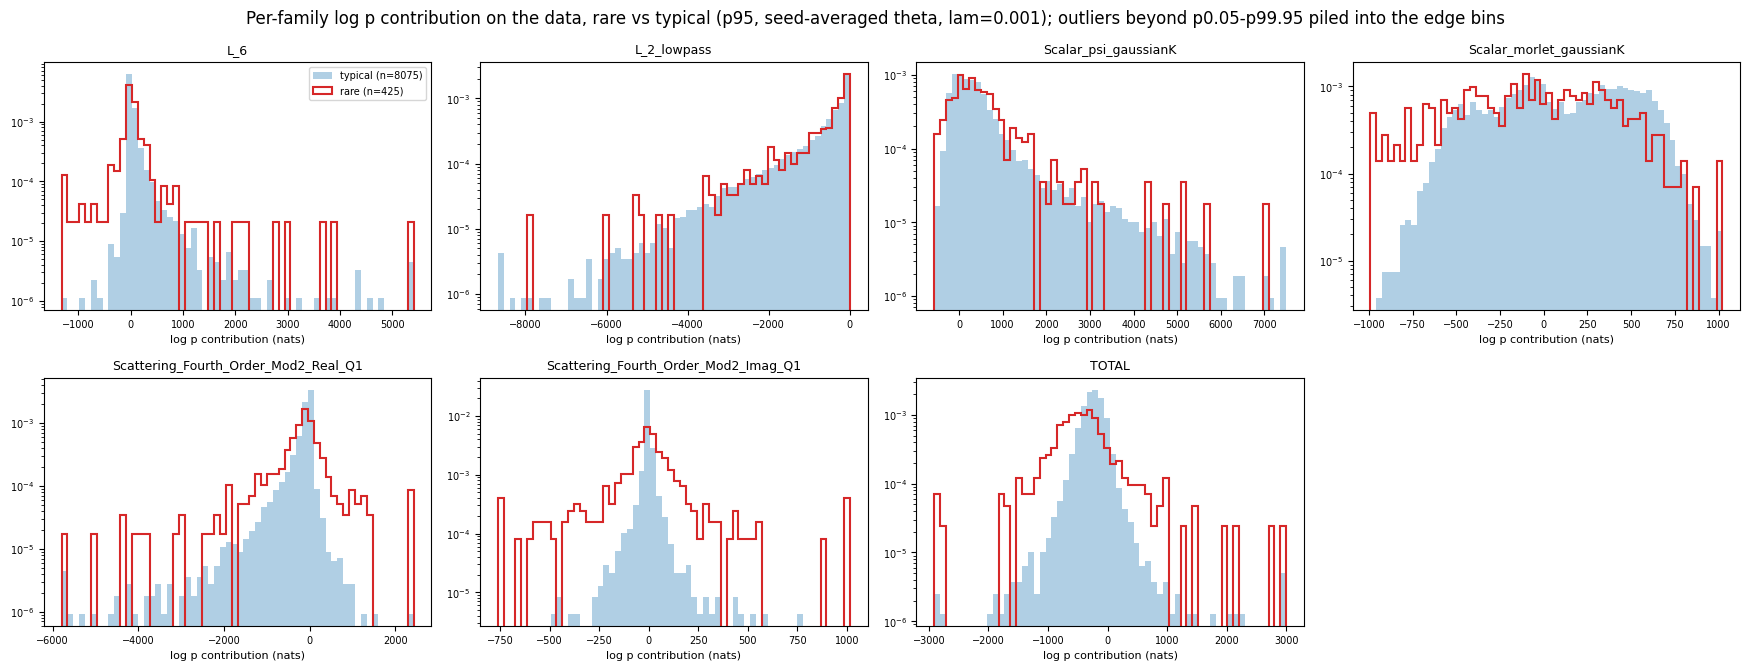

mean              std             skew  \
category                              rare typical     rare  typical    rare   
family                                                                         
L_2_lowpass                           -715    -727 1.02e+03 1.03e+03    -2.7   
L_6                                   78.8    60.2      680      313    6.49   
Scalar_morlet_gaussianK              -77.3     107      426      373 -0.0915   
Scalar_psi_gaussianK                   544     466      898      864    3.03   
Scattering_Fourth_Order_Mod2_Imag_Q1   9.2  -0.296      356     30.3    6.49   
Scattering_Fourth_Order_Mod2_Real_Q1  -267    -148      931      400   -1.43   
TOTAL                                 -427    -242      651      252  -0.573   

                                             excess kurtosis          \
category                             typical            rare typical   
family                                                                 
L_2_lowpass                            -2.79            9.94    12.8   
L_6                                     22.7            84.5     818   
Scalar_morlet_gaussianK               -0.152          -0.499  -0.957   
Scalar_psi_gaussianK                    3.35            13.5    15.5   
Scattering_Fourth_Order_Mod2_Imag_Q1    3.19            66.9     142   
Scattering_Fourth_Order_Mod2_Real_Q1   -7.53            15.7    98.2   
TOTAL                                   4.96            13.3     138   

                                            p1                p99           
category                                  rare   typical     rare  typical  
family                                                                      
L_2_lowpass                          -5.02e+03 -4.64e+03   -0.379   -0.225  
L_6                                  -1.32e+03     -46.4 2.66e+03      917  
Scalar_morlet_gaussianK                   -992      -643      782      766  
Scalar_psi_gaussianK                      -495      -324 4.67e+03 4.44e+03  
Scattering_Fourth_Order_Mod2_Imag_Q1      -763     -82.8 1.02e+03     72.7  
Scattering_Fourth_Order_Mod2_Real_Q1    -4e+03 -1.81e+03  2.1e+03      199  
TOTAL                                -1.81e+03      -818  1.5e+03      282

In [33]:
# Shape of each family's log p contribution C_F(x) = theta_F . phi_F(x) on the data (x1),
# seed-averaged theta, rare vs typical overlaid. density=True: the two categories have very
# different sizes (n printed in the legend), so compare shapes, not counts. Each panel has its own x-range
# (the Scattering families are orders of magnitude smaller than L_6).
from scipy import stats

fams = list(ranges_with_total.keys())            # all families + TOTAL
n_cols = 4
n_rows = math.ceil(len(fams) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.4 * n_cols, 3.4 * n_rows), squeeze=False)

shape_rows = []
for i, F in enumerate(fams):
    ax = axes[i // n_cols][i % n_cols]
    vals = C_bar[F]
    lo, hi = np.percentile(vals, [0.05, 99.95])   # clip extreme outliers from the bin range only
    edges = np.linspace(lo, hi, 61)
    for cat, idx in category_indices.items():
        v = vals[idx]
        ax.hist(np.clip(v, lo, hi), bins=edges, density=True, histtype='stepfilled' if cat == 'typical' else 'step',
                color=category_colors[cat], alpha=0.35 if cat == 'typical' else 1.0, lw=1.5,
                label=f'{cat} (n={len(v)})')
        shape_rows.append({'family': F, 'category': cat, 'mean': v.mean(), 'std': v.std(ddof=1),
                           'skew': stats.skew(v), 'excess kurtosis': stats.kurtosis(v),
                           'p1': np.percentile(v, 1), 'p99': np.percentile(v, 99)})
    ax.set_yscale('log')
    ax.set_title(F, fontsize=9)
    ax.set_xlabel('log p contribution (nats)', fontsize=8)
    ax.tick_params(labelsize=7)
axes[0][0].legend(fontsize=7)
for j in range(len(fams), n_rows * n_cols):
    axes[j // n_cols][j % n_cols].axis('off')
fig.suptitle(f'Per-family log p contribution on the data, rare vs typical ({P_LABEL}, seed-averaged theta, {LAM_LABEL}); '
             'outliers beyond p0.05-p99.95 piled into the edge bins')
fig.tight_layout(); plt.show()

shape_df = pd.DataFrame(shape_rows).set_index(['family', 'category'])
display(shape_df.unstack('category'))

## 2. Robustness to the rare/typical threshold

Repeat the seed-mean `D` (no bootstrap) for each percentile in `ROBUSTNESS_PERCENTILES` (Knobs; `PERCENTILE` added), split on `x1` as above. The number of rare signals at each percentile is printed below the table.

In [34]:
percentiles = sorted({*ROBUSTNESS_PERCENTILES, PERCENTILE})
table2, n_rare_p = {}, {}
for p in percentiles:
    idx_typ_p, idx_rare_p, _ = extract_rare_typical(x1, criterion='percentile', percentile=p)
    n_rare_p[f'p{p:g}'] = len(idx_rare_p)
    table2[f'p{p:g}'] = [C[F][:, idx_rare_p].mean(axis=1).mean() - C[F][:, idx_typ_p].mean(axis=1).mean()
                        for F in family_names_all]
table2_df = pd.DataFrame(table2, index=family_names_all)
display(table2_df)
print('n_rare per percentile:', n_rare_p)

,p95,p99,p99.5
L_6,18.6,-85.8,-178
L_2_lowpass,12.3,78.5,227
Scalar_psi_gaussianK,77.5,-45,-210
Scalar_morlet_gaussianK,-184,-205,-250
Scattering_Fourth_Order_Mod2_Real_Q1,-120,-256,-391
Scattering_Fourth_Order_Mod2_Imag_Q1,9.49,139,242
TOTAL,-186,-375,-559


n_rare per percentile: {'p95': 425, 'p99': 85, 'p99.5': 43}


## 3. Continuous version (no split)

Extremeness `e_i` = max over time of |lag-1 increment| of `x1[i]` (same definition and units as the split). Per family: centered log p contribution vs `e_i` (log x-axis), with the `idx_rare` signals highlighted. Table: Spearman rank correlation per family.

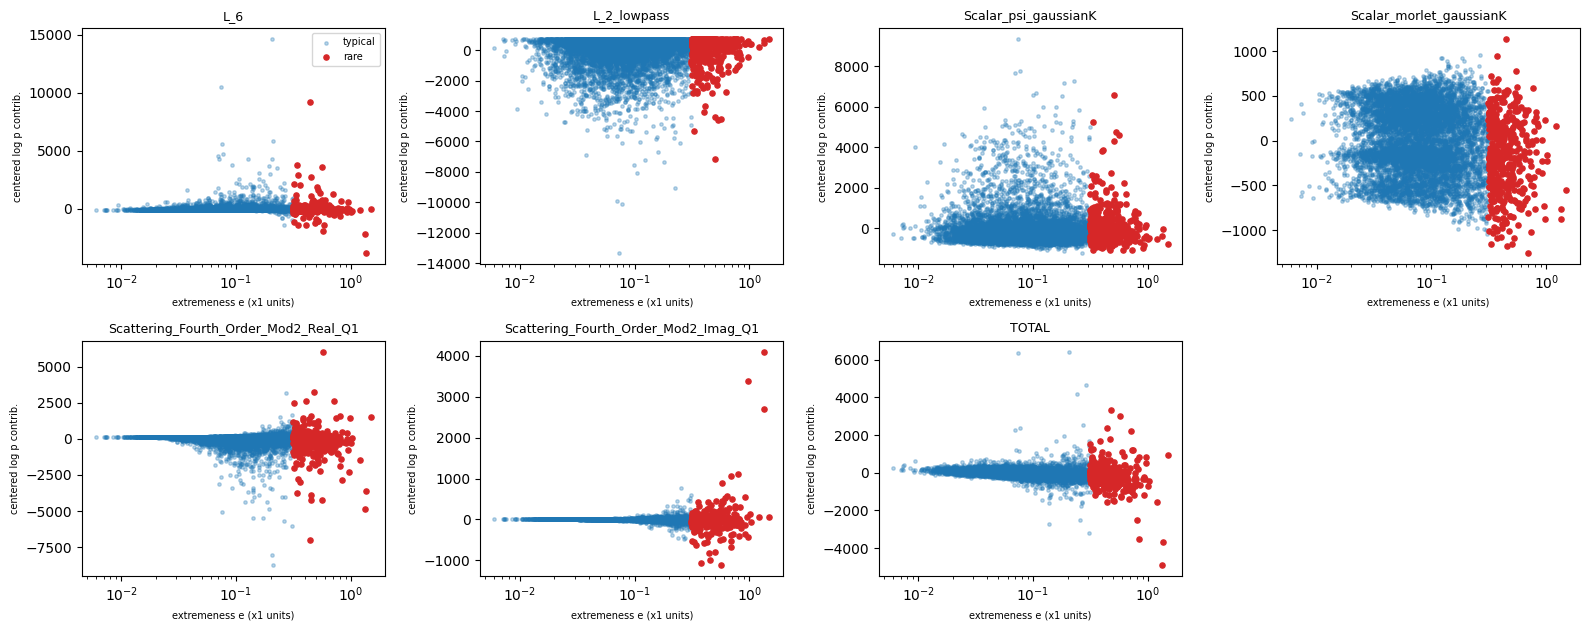

,family,spearman_rho
0,L_6,0.0747
1,L_2_lowpass,0.000756
2,Scalar_psi_gaussianK,0.0159
3,Scalar_morlet_gaussianK,-0.0792
4,Scattering_Fourth_Order_Mod2_Real_Q1,-0.211
5,Scattering_Fourth_Order_Mod2_Imag_Q1,-0.0256
6,TOTAL,-0.361


In [35]:
accel = compute_acceleration(x1)  # (n1, 1, M-1)
e = accel.abs().amax(dim=(1, 2)).cpu().numpy()  # (n1,) extremeness

n_cols = 4
n_rows = math.ceil(len(family_names_all) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3.2 * n_rows), squeeze=False)
mask_rare = np.zeros(n1, dtype=bool)
mask_rare[idx_rare] = True

spearman_rows = []
for i, F in enumerate(family_names_all):
    ax = axes[i // n_cols][i % n_cols]
    y = C_bar[F] - C_bar[F].mean()
    ax.scatter(e[~mask_rare], y[~mask_rare], s=6, alpha=0.3, color=category_colors['typical'], label='typical')
    ax.scatter(e[mask_rare], y[mask_rare], s=14, color=category_colors['rare'], label='rare')
    ax.set_xscale('log')
    ax.set_title(F, fontsize=9)
    ax.set_xlabel('extremeness e (x1 units)', fontsize=7)
    ax.set_ylabel('centered log p contrib.', fontsize=7)
    # Spearman = Pearson correlation of ranks (avoids a scipy import)
    rho = np.corrcoef(pd.Series(e).rank(), pd.Series(C_bar[F]).rank())[0, 1]
    spearman_rows.append({'family': F, 'spearman_rho': rho})
axes[0][0].legend(fontsize=7)
for j in range(len(family_names_all), n_rows * n_cols):
    axes[j // n_cols][j % n_cols].axis('off')
fig.tight_layout()
plt.show()

display(pd.DataFrame(spearman_rows))

## 4. Compensation between families

Correlation matrix of the families' log p contributions (seed-averaged $\theta$) across all `n1` signals. Then the sign-aware variance decomposition $\sum_{F\neq G}\mathrm{Cov}(C_F,C_G)=\mathrm{Var}(\mathrm{TOTAL})-\sum_F\mathrm{Var}(C_F)$: positive means the cross-family covariances **add** variance, negative means they **remove** it (compensation). The largest pairwise terms $2\,\mathrm{Cov}(C_F,C_G)$ are listed with their sign.

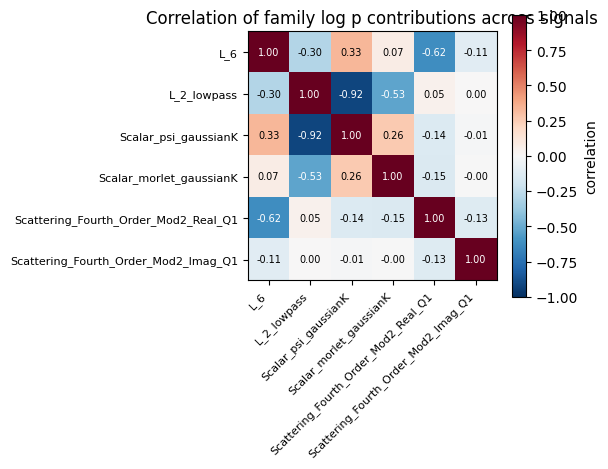

Var(TOTAL) = 8.307e+04
sum_F Var(C_F) = 2.262e+06
sum_(F!=G) Cov(C_F, C_G) = Var(TOTAL) - sum_F Var(C_F) = -2.179e+06  ->  cross-family covariance removes 96.3% of sum_F Var(C_F)
3 largest pairwise terms 2*Cov(C_F, C_G) by |value| (+ reinforces, - compensates):
  -1.632e+06   L_2_lowpass & Scalar_psi_gaussianK
  -4.115e+05   L_2_lowpass & Scalar_morlet_gaussianK
  -2.062e+05   L_6 & L_2_lowpass


In [36]:
fam_only = list(family_ranges.keys())
C_mat = np.stack([C_bar[F] for F in fam_only], axis=0)  # (n_families, n1)
corr = np.corrcoef(C_mat)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(fam_only))); ax.set_xticklabels(fam_only, rotation=45, ha='right', fontsize=8)
ax.set_yticks(range(len(fam_only))); ax.set_yticklabels(fam_only, fontsize=8)
for i in range(len(fam_only)):
    for j in range(len(fam_only)):
        ax.text(j, i, f'{corr[i, j]:.2f}', ha='center', va='center', fontsize=7,
                color='white' if abs(corr[i, j]) > 0.5 else 'black')
fig.colorbar(im, ax=ax, label='correlation')
ax.set_title('Correlation of family log p contributions across signals')
fig.tight_layout()
plt.show()

var_total = C_bar['TOTAL'].var(ddof=1)
var_sum_families = sum(C_bar[F].var(ddof=1) for F in fam_only)
cross_cov = var_total - var_sum_families   # = sum_{F != G} Cov(C_F, C_G)
print(f"Var(TOTAL) = {var_total:.4g}")
print(f"sum_F Var(C_F) = {var_sum_families:.4g}")
print(f"sum_(F!=G) Cov(C_F, C_G) = Var(TOTAL) - sum_F Var(C_F) = {cross_cov:.4g}  ->  cross-family covariance "
      f"{'adds' if cross_cov > 0 else 'removes'} {100 * abs(cross_cov) / var_sum_families:.1f}% of sum_F Var(C_F)")

cov_fam = np.cov(C_mat, ddof=1)
pair_terms = [(2 * cov_fam[i, j], fam_only[i], fam_only[j])
              for i in range(len(fam_only)) for j in range(i + 1, len(fam_only))]
print("3 largest pairwise terms 2*Cov(C_F, C_G) by |value| (+ reinforces, - compensates):")
for term, F, G in sorted(pair_terms, key=lambda t: -abs(t[0]))[:3]:
    print(f"  {term:+.4g}   {F} & {G}")

## 5. Residual variance: which families are irreplaceable?

With $p_\theta\propto e^{+\theta^\top\varphi}$, write $C_F(x)=\theta_F^\top\varphi_F(x)$, so $\log p_\theta=\sum_F C_F-\log Z(\theta)$. The raw variance $\mathrm{Var}[C_F]$ overstates a family's role when other families can reproduce part of $C_F$ (compensation, near-collinear features). We therefore measure the part they cannot reproduce:
$$R_F=\min_\beta\,\mathrm{Var}\big[C_F-\beta^\top\varphi_{\bar F}\big].$$

**Why this quantity.** For an exponential family, $\mathrm{KL}(p_\theta\|p_{\theta+\delta})=\tfrac12\,\delta^\top\Sigma\,\delta+O(|\delta|^3)$ with $\Sigma=\mathrm{Cov}_{p_\theta}[\varphi]$ (standard). Removing $F$ ($\delta_F=-\theta_F$) and optimally refitting the other couplings costs, to second order, $\tfrac12 R_F$ (a Schur complement of $\Sigma$). So $R_F$ measures the information lost by dropping $F$. Computed on the rare subset, it is the same statement for $p_\theta(x\mid x\in\text{rare})$.

We report three levels, $\mathrm{Var}[C_F]\ \ge\ R_F^{\rm fam}\ \ge\ R_F$, where $R_F^{\rm fam}$ only lets other families rescale ($\beta$ acting on the $C_G$, $G\neq F$), and $R_F$ allows a full refit on the other families' features (ridge, cross-fitted). For a pair, $\mathrm{Var}[C_F+C_G]$ upper-bounds the cost of removing both: if small, $F$ and $G$ are **redundant** (each can replace the other), not individually irrelevant.

**Caveats.** (i) Variances are computed on data, a proxy for the model covariance. (ii) The expansion is local: it underestimates the cost of confining terms whose removal breaks normalizability; for such terms (plausibly L_6) small variance does not mean irrelevance. (iii) Small $R_F$ means *replaceable*, not *physically meaningless*.

*Implementation.* Both $R_F^{\rm fam}$ (least squares) and $R_F$ (ridge) are 2-fold cross-fitted on the same random split of each set: fit on one half, take residuals on the other, swap, pool. Ridge regressors are standardized on the training fold, with penalty $n_{\rm train}\,\lambda\,|\beta|^2$ and one $\lambda$ chosen on `all` (printed below).

In [37]:
sets = {'all': np.arange(n1), 'typical': np.array(idx_typical), 'rare': np.array(idx_rare)}
rng = np.random.default_rng(0)   # assumption: random 2-fold split, fixed seed
folds = {name: np.array_split(rng.permutation(idx), 2) for name, idx in sets.items()}
C64 = {F: C[F].astype(np.float64) for F in fam_only}          # (n_seeds, n1), from the energy cell
# regressors: the other families' features, from each seed's own phi (all the same object if PHI_SHARED)
X_notF = {k: {F: np.delete(phi_by_seed[k], np.r_[a:b], axis=1) for F, (a, b) in family_ranges.items()}
          for k in (seed_keys if not PHI_SHARED else [REFERENCE_SEED])}
X_of = lambda s, F: X_notF[seed_keys[s] if not PHI_SHARED else REFERENCE_SEED][F]

def crossfit_resid_var(X, Y, fold_pair, lam):
    """2-fold cross-fitted residual variance of Y (n1, k) regressed on X (n1, p) with intercept,
    columns of X standardized on the training fold; lam=None -> least squares, else ridge with
    penalty n_train * lam * |beta|^2. fold_pair holds row indices into X/Y. Returns (k,)."""
    resid = []
    for tr, te in (fold_pair, fold_pair[::-1]):
        mu, sd = X[tr].mean(0), X[tr].std(0)
        sd[sd == 0] = 1.0
        Xtr, Xte = (X[tr] - mu) / sd, (X[te] - mu) / sd
        ybar = Y[tr].mean(0)
        pen = 0.0 if lam is None else len(tr) * lam
        beta = np.linalg.solve(Xtr.T @ Xtr + pen * np.eye(X.shape[1]), Xtr.T @ (Y[tr] - ybar))
        resid.append(Y[te] - ybar - Xte @ beta)
    return np.concatenate(resid).var(axis=0, ddof=1)

def r_feat(F, set_name, lam):
    """(n_seeds,) ridge residual variance of C_F on the other families' features."""
    if PHI_SHARED:   # one regression, every seed a column of Y
        return crossfit_resid_var(X_of(0, F), C64[F].T, folds[set_name], lam)
    return np.array([crossfit_resid_var(X_of(s, F), C64[F][s][:, None], folds[set_name], lam)[0]
                     for s in range(n_seeds)])

def var_raw(F, set_name):
    return C64[F][:, sets[set_name]].var(axis=1, ddof=1)       # (n_seeds,)

# Ridge lambda: one value for all families, minimizing mean_{F, seeds} R_feat/var_raw on 'all'.
lam_grid = np.logspace(-6, 0, 7)
lam_score = [np.mean([(r_feat(F, 'all', lam) / var_raw(F, 'all')).mean() for F in fam_only]) for lam in lam_grid]
lam_ridge = lam_grid[int(np.argmin(lam_score))]
print("mean R_feat/var_raw on 'all' per lambda: "
      + ", ".join(f"{lam:.0e}: {s:.4g}" for lam, s in zip(lam_grid, lam_score)))
print(f"ASSUMPTION: ridge lambda fixed at {lam_ridge:.0e} for every set/family"
      + ("  (WARNING: at the edge of the grid)" if lam_ridge in (lam_grid[0], lam_grid[-1]) else ""))

res = {}   # (set, F) -> per-seed arrays
for set_name in sets:
    for F in fam_only:
        others = [G for G in fam_only if G != F]
        r_fam = np.array([crossfit_resid_var(np.stack([C64[G][s] for G in others], axis=1),
                                             C64[F][s][:, None], folds[set_name], None)[0]
                          for s in range(n_seeds)])
        rf = r_feat(F, set_name, lam_ridge)
        v = var_raw(F, set_name)
        res[set_name, F] = {'var_raw': v, 'R_fam': r_fam, 'R_feat': rf, 'R_feat/var_raw': rf / v}

# Bootstrap over rare signals, seed-averaged C_bar and the reference seed's features, for
# R_feat/var_raw. Resampled within each fold, so a duplicated signal never sits in both halves.
rng = np.random.default_rng(BOOT_SEED)
n_boot = N_BOOT
f0, f1 = folds['rare']
boot_ratio = np.empty((n_boot, len(fam_only)))
for bi in range(n_boot):
    bfolds = (rng.choice(f0, len(f0)), rng.choice(f1, len(f1)))
    bidx = np.concatenate(bfolds)
    for j, F in enumerate(fam_only):
        y = C_bar[F].astype(np.float64)[:, None]
        boot_ratio[bi, j] = crossfit_resid_var(X_of(0, F), y, bfolds, lam_ridge)[0] / y[bidx].var(ddof=1)
rare_point = [crossfit_resid_var(X_of(0, F), C_bar[F].astype(np.float64)[:, None], folds['rare'], lam_ridge)[0]
              / C_bar[F][idx_rare].var(ddof=1) for F in fam_only]

sd = lambda a: a.std(ddof=1) if len(a) > 1 else np.nan
quantities = ['var_raw', 'R_fam', 'R_feat', 'R_feat/var_raw']
table_rv = pd.DataFrame({(set_name, q): [f"{res[set_name, F][q].mean():.3g} ± {sd(res[set_name, F][q]):.2g}"
                                         for F in fam_only]
                         for set_name in sets for q in quantities}, index=fam_only)
table_rv[('rare', 'R_feat/var_raw, mean theta ± boot SE')] = [
    f"{p:.3g} ± {se:.2g}" for p, se in zip(rare_point, boot_ratio.std(axis=0, ddof=1))]
print(f"mean ± std across {n_seeds} seeds; set sizes: " + ", ".join(f"{k} = {len(v)}" for k, v in sets.items())
      + f"; bootstrap: {n_boot} resamples of the rare signals")
display(table_rv)

n_viol = sum(int((r['R_fam'] > r['var_raw']).sum() + (r['R_feat'] > r['R_fam']).sum()) for r in res.values())
print(f"(set, family, seed) cases breaking var_raw >= R_fam >= R_feat (estimation noise): "
      f"{n_viol} of {2 * len(res) * n_seeds} comparisons")

mean R_feat/var_raw on 'all' per lambda: 1e-06: 59.02, 1e-05: 16.43, 1e-04: 7.466, 1e-03: 2.34, 1e-02: 0.5433, 1e-01: 0.354, 1e+00: 0.4038
ASSUMPTION: ridge lambda fixed at 1e-01 for every set/family
mean ± std across 5 seeds; set sizes: all = 8500, typical = 8075, rare = 425; bootstrap: 1000 resamples of the rare signals


all                      \
                                                 var_raw               R_fam   
L_6                                   2.86e+05 ± 1.3e+05  1.56e+05 ± 6.3e+04   
L_2_lowpass                             5.84e+06 ± 1e+07  5.36e+05 ± 4.7e+05   
Scalar_psi_gaussianK                    3.54e+07 ± 3e+07  4.24e+05 ± 2.1e+05   
Scalar_morlet_gaussianK               3.51e+07 ± 3.6e+07  4.69e+05 ± 2.2e+05   
Scattering_Fourth_Order_Mod2_Real_Q1  5.61e+05 ± 3.7e+05  2.57e+05 ± 1.8e+05   
Scattering_Fourth_Order_Mod2_Imag_Q1  6.75e+04 ± 2.7e+04  7.62e+04 ± 4.3e+04   

                                                                            \
                                                  R_feat    R_feat/var_raw   
L_6                                   1.29e+05 ± 8.3e+04      0.421 ± 0.15   
L_2_lowpass                           1.92e+05 ± 3.4e+05  0.0328 ± 3.8e-16   
Scalar_psi_gaussianK                    1.35e+06 ± 8e+05    0.0489 ± 0.023   
Scalar_morlet_gaussianK               4.31e+05 ± 4.2e+05   0.0135 ± 0.0015   
Scattering_Fourth_Order_Mod2_Real_Q1  1.58e+05 ± 5.7e+04      0.467 ± 0.44   
Scattering_Fourth_Order_Mod2_Imag_Q1  7.16e+04 ± 1.5e+04       1.14 ± 0.31   

                                                 typical                      \
                                                 var_raw               R_fam   
L_6                                   2.18e+05 ± 1.3e+05  1.17e+05 ± 7.5e+04   
L_2_lowpass                             5.84e+06 ± 1e+07  4.36e+05 ± 3.3e+05   
Scalar_psi_gaussianK                  3.44e+07 ± 2.9e+07  3.28e+05 ± 1.4e+05   
Scalar_morlet_gaussianK               3.39e+07 ± 3.5e+07  3.55e+05 ± 1.6e+05   
Scattering_Fourth_Order_Mod2_Real_Q1  3.89e+05 ± 3.3e+05   1.4e+05 ± 1.2e+05   
Scattering_Fourth_Order_Mod2_Imag_Q1  6.95e+03 ± 3.6e+03  6.99e+03 ± 3.6e+03   

                                                                            \
                                                  R_feat    R_feat/var_raw   
L_6                                   9.72e+04 ± 7.7e+04      0.437 ± 0.15   
L_2_lowpass                           1.03e+05 ± 1.8e+05  0.0176 ± 9.3e-17   
Scalar_psi_gaussianK                  1.15e+06 ± 7.5e+05     0.041 ± 0.012   
Scalar_morlet_gaussianK               5.07e+05 ± 5.1e+05   0.0157 ± 0.0012   
Scattering_Fourth_Order_Mod2_Real_Q1  4.72e+04 ± 2.8e+04      0.217 ± 0.21   
Scattering_Fourth_Order_Mod2_Imag_Q1  7.33e+03 ± 3.6e+03      1.07 ± 0.062   

                                                    rare                      \
                                                 var_raw               R_fam   
L_6                                   1.59e+06 ± 1.5e+06  8.03e+05 ± 5.5e+05   
L_2_lowpass                             5.77e+06 ± 1e+07    6.84e+05 ± 4e+05   
Scalar_psi_gaussianK                  5.23e+07 ± 4.7e+07  9.05e+05 ± 2.3e+05   
Scalar_morlet_gaussianK               5.63e+07 ± 5.8e+07  1.11e+06 ± 9.3e+04   
Scattering_Fourth_Order_Mod2_Real_Q1  3.57e+06 ± 1.6e+06    1.76e+06 ± 2e+05   
Scattering_Fourth_Order_Mod2_Imag_Q1  1.21e+06 ± 5.6e+05  1.33e+06 ± 8.3e+05   

                                                                            \
                                                  R_feat    R_feat/var_raw   
L_6                                   7.35e+05 ± 9.2e+05      0.431 ± 0.13   
L_2_lowpass                           4.76e+05 ± 8.4e+05  0.0825 ± 3.4e-16   
Scalar_psi_gaussianK                  4.92e+06 ± 3.5e+06     0.111 ± 0.044   
Scalar_morlet_gaussianK               4.07e+06 ± 4.3e+06   0.0685 ± 0.0077   
Scattering_Fourth_Order_Mod2_Real_Q1  3.26e+06 ± 3.3e+06      0.928 ± 0.69   
Scattering_Fourth_Order_Mod2_Imag_Q1  1.41e+06 ± 5.7e+05       1.26 ± 0.45   

                                                                           
                                     R_feat/var_raw, mean theta ± boot SE  
L_6                                                           0.39 ± 0.17  
L_2_lowpass                

(set, family, seed) cases breaking var_raw >= R_fam >= R_feat (estimation noise): 50 of 180 comparisons


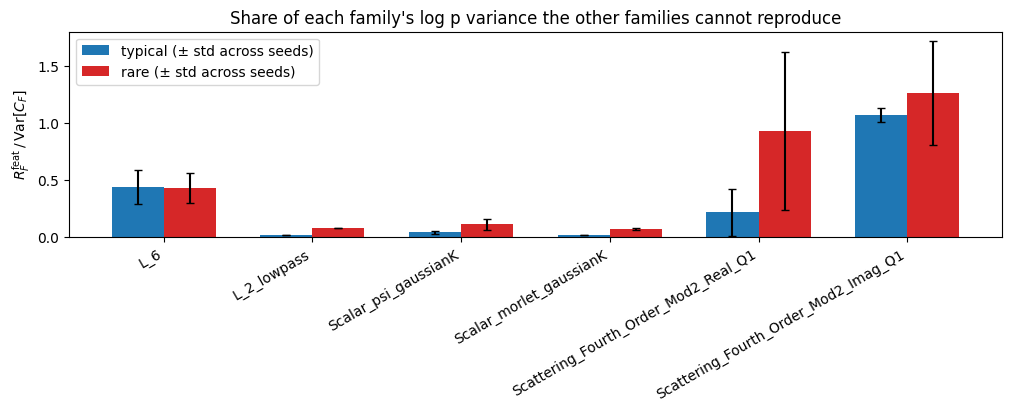

typical: lowest R_feat/var_raw (most replaceable) = Scalar_morlet_gaussianK (0.0157); highest (least replaceable) = Scattering_Fourth_Order_Mod2_Imag_Q1 (1.07)
rare: lowest R_feat/var_raw (most replaceable) = Scalar_morlet_gaussianK (0.0685); highest (least replaceable) = Scattering_Fourth_Order_Mod2_Imag_Q1 (1.26)

Rare set: Var[C_F + C_G] / (Var[C_F] + Var[C_G])


,L_6,L_2_lowpass,Scalar_psi_gaussianK,Scalar_morlet_gaussianK,Scattering_Fourth_Order_Mod2_Real_Q1,Scattering_Fourth_Order_Mod2_Imag_Q1
L_6,NaN,0.875,1.17,1.1,0.476,0.821
L_2_lowpass,0.875,NaN,0.122,0.654,1.02,1.01
Scalar_psi_gaussianK,1.17,0.122,NaN,1.17,0.948,0.971
Scalar_morlet_gaussianK,1.1,0.654,1.17,NaN,0.831,0.977
Scattering_Fourth_Order_Mod2_Real_Q1,0.476,1.02,0.948,0.831,NaN,0.78
Scattering_Fourth_Order_Mod2_Imag_Q1,0.821,1.01,0.971,0.977,0.78,NaN


L_6 + Scattering_Fourth_Order_Mod2_Real_Q1: 0.476


In [38]:
fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
xpos = np.arange(len(fam_only))
for i, set_name in enumerate(['typical', 'rare']):
    ratio = np.stack([res[set_name, F]['R_feat/var_raw'] for F in fam_only])   # (n_families, n_seeds)
    ax.bar(xpos + (i - 0.5) * 0.35, ratio.mean(1), 0.35, yerr=ratio.std(1, ddof=1), capsize=3,
           color=category_colors[set_name], label=f'{set_name} (± std across seeds)')
ax.set_xticks(xpos); ax.set_xticklabels(fam_only, rotation=30, ha='right')
ax.set_ylabel(r'$R_F^{\rm feat}\,/\,\mathrm{Var}[C_F]$')
ax.set_title('Share of each family\'s log p variance the other families cannot reproduce')
ax.legend()
plt.show()

for set_name in ['typical', 'rare']:
    r = {F: res[set_name, F]['R_feat/var_raw'].mean() for F in fam_only}
    order = sorted(r, key=r.get)
    print(f"{set_name}: lowest R_feat/var_raw (most replaceable) = {order[0]} ({r[order[0]]:.3g}); "
          f"highest (least replaceable) = {order[-1]} ({r[order[-1]]:.3g})")

# Pair check on the rare set, seed-averaged theta: Var[C_F + C_G] / (Var[C_F] + Var[C_G])
# (= 1 if uncorrelated, << 1 means F and G compensate each other; diagonal left blank).
C_rare = np.stack([C_bar[F][idx_rare] for F in fam_only]).astype(np.float64)
v_rare = C_rare.var(axis=1, ddof=1)
pair_ratio = pd.DataFrame([[np.nan if i == j else (C_rare[i] + C_rare[j]).var(ddof=1) / (v_rare[i] + v_rare[j])
                            for j in range(len(fam_only))] for i in range(len(fam_only))],
                          index=fam_only, columns=fam_only)
print("\nRare set: Var[C_F + C_G] / (Var[C_F] + Var[C_G])")
display(pair_ratio)
print(f"L_6 + {REAL_KEY}: {pair_ratio.loc['L_6', REAL_KEY]:.4g}")

## 6. Model samples

Each seed's final samples (`saved_results/samples/<config>.pt`), with φ from that seed's own fitted potentials and paired with that seed's θ.

In [39]:
sample_path = {}   # seed_key -> path of that seed's samples file
for key in seed_keys:
    p = root / "saved_results" / "samples" / config_by_seed[key]
    p_pt = p.with_name(p.name + ".pt")
    path = p_pt if p_pt.exists() else (p if p.exists() else None)
    if path is not None:
        sample_path[key] = path
print(f"{len(sample_path)}/{len(seed_keys)} seeds have a samples file")
assert sample_path, 'no samples file found: section 6 needs at least one'

model_norm_checked = False
needs_norm = None
C_model = {}   # seed_key -> {family: (n_model,) array}, includes 'TOTAL'
e_model = {}   # seed_key -> (n_model,) extremeness, same lag-1/max|.| definition and units as the split on x1

for key, path in sample_path.items():
    x_final = torch.load(path, map_location='cpu').reshape(-1, 1, M)

    if not model_norm_checked:
        m, s = x_final.mean().item(), x_final.std().item()
        needs_norm = not (abs(m) < 0.05 and abs(s - 1) < 0.05)
        print(f"model samples {tuple(x_final.shape)}: mean={m:.4g} std={s:.4g} -> "
              f"{'applying' if needs_norm else 'skipping'} normalize() (checked on {key} only)")
        model_norm_checked = True

    x_model = normalize(x_final) if needs_norm else x_final   # CPU; same tensor for phi and extremeness
    phi_model = compute_phi_X(potentials_by_seed[key], x_model.to(device)).detach().cpu().double().numpy()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    s_idx = seed_keys.index(key)
    c_this = {F: phi_model[:, a:b] @ reg_all_np[s_idx, a:b] for F, (a, b) in family_ranges.items()}
    c_this['TOTAL'] = sum(c_this.values())
    C_model[key] = c_this

    accel_model = compute_acceleration(x_model)
    e_model[key] = accel_model.abs().amax(dim=tuple(range(1, accel_model.ndim))).numpy()

print(f"Computed model-sample phi/log-p contributions for {len(C_model)} seeds.")

5/5 seeds have a samples file
model samples (8500, 1, 256): mean=0.005387 std=0.9998 -> skipping normalize() (checked on seed900 only)
Computed model-sample phi/log-p contributions for 5 seeds.


### 6a. Data vs model: TOTAL log p contribution and per-family std

Same-seed theta on data (from section 1's `C`) vs on that seed's model samples, pooled across seeds.

L_6                                           data std=     536.2   model std=     496.7
L_2_lowpass                                   data std=      2870   model std=      2866
Scalar_psi_gaussianK                          data std=      7901   model std=      7911
Scalar_morlet_gaussianK                       data std=      8851   model std=      8849
Scattering_Fourth_Order_Mod2_Real_Q1          data std=     775.7   model std=     829.2
Scattering_Fourth_Order_Mod2_Imag_Q1          data std=     259.9   model std=     282.2


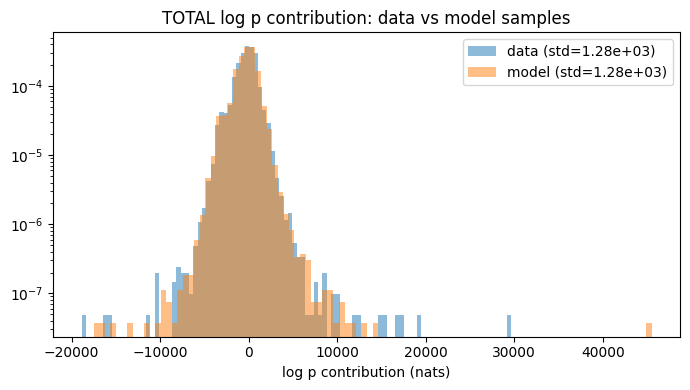

TOTAL mean: data = -250.9, model = -256.2 (each seed's own theta, pooled over 5 seeds)


In [40]:
model_keys = list(C_model.keys())
for F in family_names_all:
    data_vals = np.concatenate([C[F][seed_keys.index(k)] for k in model_keys])
    model_vals = np.concatenate([C_model[k][F] for k in model_keys])
    if F == 'TOTAL':
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.hist(data_vals, bins=100, density=True, alpha=0.5, color='tab:blue',
                label=f'data (std={data_vals.std():.3g})')
        ax.hist(model_vals, bins=100, density=True, alpha=0.5, color='tab:orange',
                label=f'model (std={model_vals.std():.3g})')
        ax.set_yscale('log'); ax.legend()
        ax.set_xlabel('log p contribution (nats)')
        ax.set_title('TOTAL log p contribution: data vs model samples')
        fig.tight_layout(); plt.show()
        print(f"TOTAL mean: data = {data_vals.mean():.4g}, model = {model_vals.mean():.4g} "
              f"(each seed's own theta, pooled over {len(model_keys)} seeds)")
    else:
        print(f"{F:45s} data std={data_vals.std():10.4g}   model std={model_vals.std():10.4g}")

**Caveat.** With `THETA_SOURCE = 'theta_t'` (the default here, since there is no offline solve yet) the θ paired with the samples is the one that drove the sampler at the last step. If you switch to `'theta_reg'` once an offline solve exists, the MGD samples are not guaranteed to be samples of $p_{\Theta_{\rm reg}}$: $\Theta_{\rm reg}$ is a separate regularised fit (and depends on `LAM`), and a gap between the data and model TOTAL means is read with that in mind.


### 6b. Rare fraction: model vs data, same cutoff

Apply the data cutoff `cutoff_rare` (at `PERCENTILE`, plus p95/p99 for reference) (from the split on `x1`) to the model samples' max |lag-1 increment|, computed in the same normalized units.

In [41]:
data_rare_frac = len(idx_rare) / n1
cut_rows = [(P_LABEL, cutoff_rare, data_rare_frac)]
for p in (95, 99):
    if p != PERCENTILE:
        cut_p = extract_rare_typical(x1, criterion='percentile', percentile=p)[2]['cutoff']
        cut_rows.append((f'p{p}', cut_p, (e_split > cut_p).mean()))

print("CAVEAT: cutoffs and both extremeness values are in x1's normalized units; model samples are taken to "
      "already be in those units (mean/std checked on one seed, in the loading cell above).")
rows = []
for name, cut, data_frac in cut_rows:
    per_seed = np.array([(e_model[k] > cut).mean() for k in C_model])
    pooled = np.concatenate([e_model[k] for k in C_model])
    rows.append({'data cutoff': name, 'cutoff (x1 units)': cut, 'data fraction': data_frac,
                 'model fraction (pooled)': (pooled > cut).mean(),
                 'model n above (pooled)': int((pooled > cut).sum()), 'model n (pooled)': len(pooled),
                 'model fraction, std across seeds': per_seed.std(ddof=1) if len(per_seed) > 1 else np.nan})
display(pd.DataFrame(rows))

CAVEAT: cutoffs and both extremeness values are in x1's normalized units; model samples are taken to already be in those units (mean/std checked on one seed, in the loading cell above).


,data cutoff,cutoff (x1 units),data fraction,model fraction (pooled),model n above (pooled),model n (pooled),"model fraction, std across seeds"
0,p95,0.313,0.05,0.0263,1116,42500,0.000866
1,p99,0.553,0.01,0.0064,272,42500,0.000395


---
# 🧪 TEST 2026-10-07: separate testing experiment (not part of the rare/typical analysis)

**Everything from here to the "END OF TEST 2026-10-07" cell belongs to this test.** The cells above don't depend on it. These cells only read what the cells above built (`potentials_ref`, `x1`, `cfg`, `reg_all_np`, ...). They change none of it: every new variable starts with `st_` or `sn_`.

Two open questions from the Gram/θ recap:

- **(A) Late moment misfit.** 11 fine-channel inner-region moments (`Scalar_psi_gaussianK[0,1,2,3,5,7,13,34,35]`, `Scalar_morlet_gaussianK[0,6]`) end 1-16% off, in **both** ridge arms and whether the Gram is well or badly conditioned. Hypothesis: one step's noise is wider than these narrow regions, so the walkers get pushed out of them.
- **(B) Coarse L_6 signs.** In Θ_reg, the coarse `L_6` coefficients (filter 4, period ~32 samples, positive in 4/5 seeds) may be positive. Then $p_\theta$ might not be normalisable along slow oscillations.

How to run: (A) needs only the potentials and the data (it ignores θ). (B) uses `reg_all_np`, so run it with `THETA_SOURCE = 'theta_reg'` (`LAM = 1e-3`), and optionally again with `'theta_t'`. (A) takes seconds on GPU and minutes on CPU (lower `N_W` if needed).

### TEST 2026-10-07 (A): one step of the sampler, starting from exactly the right moments

**What it does.**
1. Take `N_W` data signals and fresh noise and put the walkers **exactly on the interpolant** at a time $t_0$. Their moments are then exactly right at $t_0$.
2. Make **one step** of the run's own code (`iteration_step_projection`: drift + noise $\sqrt{2h}\,\sigma$, then the single linear corrector; same ridge, mask and float64 as the run) to $t_0+h$.
3. Compare with the moments of the **same** interpolant signals at $t_0+h$. Walkers and target come from the same signals, so there is no sampling offset: whatever error remains is made by the step.
4. Repeat with steps 4× and 16× smaller than the run's step at that $t_0$, and do `N_EXTRA` extra corrector passes (the run does only one).

Error = |walker mean − target| / scale, where scale ≈ the moment's data value. That is close to the run's "own-scale" error.

**How to read it.**
- Missed moments **much worse than the others** after the run's step, and **better with smaller h** → the step itself loses them, which supports the hypothesis.
  - If the **extra passes remove it** → one linear corrector per step is not enough (fix: iterate the corrector).
  - If the **extra passes don't remove it** → the corrector can't push walkers back (fix: smaller steps where it matters).
- Missed moments **about as good as the others** → one step from a perfect start is fine. The misfit then builds up over many steps, and the hypothesis in this simple form is wrong.
- `steady lag guess` = (error after one step) / (1 − ρ), where ρ = how much one extra pass leaves. It's a rough guess of the lag that builds up, to compare with the run's misfit (e.g. `Scalar_psi[34]` ~0.35-0.4 at 1−t ≈ 1e-3). It assumes every step behaves the same, so treat it as an order of magnitude only.

In [ ]:
# === TEST 2026-10-07 (A): one-step test of the late moment misfit. Not part of the rare/typical analysis. ===
# Uses potentials_ref, x1, cfg, exp_dir_by_seed, REFERENCE_SEED, device. theta / Theta_reg are NOT used.
# All variables made here start with st_ so nothing above is overwritten.
import time
from time_schedules import build_time_grid

N_W = 2000                              # walkers (random subset of x1); no sampling offset by construction
ONE_MINUS_T = [1e-1, 1e-2, 1e-3, 1e-4]  # where to test (1 - t0); the misfit appears for 1 - t < 0.05
H_FACTORS = [1, 1/4, 1/16]              # step = the run's step at t0 times these
N_EXTRA = 3                             # extra corrector passes after the run's single one
STEP_SEED = 0
# the 11 moments above 1% at the end of BOTH noSm30 arms (index inside the family, gram_along_transport 10-02)
MISSED = {'Scalar_psi_gaussianK': [0, 1, 2, 3, 5, 7, 13, 34, 35], 'Scalar_morlet_gaussianK': [0, 6]}

st_t_run, _ = build_time_grid(SimpleNamespace(**cfg))          # the run's own grid (two_phase, float64)
st_gen = torch.Generator().manual_seed(STEP_SEED)
st_idx = torch.randperm(x1.shape[0], generator=st_gen)[:N_W]
st_data = x1[st_idx].to(device)
st_noise0 = torch.randn(st_data.shape, generator=st_gen).to(device)
st_solver = SDE(st_data, N_W, N_W, st_t_run[:2].clone(), cfg['sigma'], dict(potentials_ref), cfg['batch_size'],
                device=device, regularization=cfg['regularization'], interpolant=cfg['interpolant'],
                x_0=st_noise0, x_k=st_data.clone(), solve_float64=cfg.get('solve_float64', False),
                potentials_save_dir=exp_dir_by_seed[REFERENCE_SEED] / 'fitted_potentials')   # loads, never refits

st_offs = dict(zip(st_solver.potentials, st_solver.indices_potentials[:-1]))
st_missed_cols = np.array([st_offs[F] + i for F, idx in MISSED.items() for i in idx])
st_labels = np.array(st_solver.potential_labels)
st_is_missed = np.zeros(st_solver.num_potentials, bool); st_is_missed[st_missed_cols] = True
st_mbar = lambda x: st_solver.compute_moments(x).double().mean(0)
st_data_mom = st_mbar(st_data)

st_rows, st_per_stat = [], {}
for st_omt in ONE_MINUS_T:
    st_k = min(int(torch.searchsorted(st_t_run, torch.tensor(1 - st_omt, dtype=st_t_run.dtype))), len(st_t_run) - 2)
    st_t0, st_h_run = float(st_t_run[st_k]), float(st_t_run[st_k + 1] - st_t_run[st_k])
    for st_f in H_FACTORS:
        st_tic = time.time()
        st_h = st_h_run * st_f
        st_solver.t = torch.tensor([st_t0, st_t0 + st_h], dtype=torch.float64)
        st_solver._rhs_dt_cache = None
        st_x_start = st_solver.compute_interpolant(0)                   # exact moments at t0
        st_target = st_mbar(st_solver.compute_interpolant(1))
        # own scale ~ the run's max_t |target| (its headline metric); for these region shares ~ the data value
        st_scale = torch.maximum(st_target.abs(), st_data_mom.abs())
        st_ok = (st_scale > cfg.get('moment_threshold', 1e-8)).cpu().numpy()
        st_err = lambda x: ((st_mbar(x) - st_target) / st_scale).cpu().numpy()
        torch.manual_seed(STEP_SEED)                                    # same standard-normal draw for every h
        st_x_next, st_y, *_ = st_solver.iteration_step_projection(st_x_start, 0)
        st_errs = [st_err(st_y), st_err(st_x_next)]                     # after predictor, after the run's corrector
        st_x = st_x_next
        for _ in range(N_EXTRA):
            st_th, _ = st_solver.compute_theta(st_x, 0)
            st_x = st_x + st_solver.compute_grad_phi_projected(st_x, st_th)
            st_errs.append(st_err(st_x))
        st_E = np.abs(np.stack(st_errs))                                # (2 + N_EXTRA, r)
        st_m, st_o = st_E[:, st_is_missed & st_ok], st_E[:, ~st_is_missed & st_ok]
        st_rho = np.median(st_m[2] / np.maximum(st_m[1], 1e-300)) if N_EXTRA else np.nan
        st_rows.append({'1-t0': st_omt, 'h/h_run': st_f, 'h': st_h,
                        'missed: after predictor': np.median(st_m[0]),
                        'missed: after run step': np.median(st_m[1]), 'missed: max after run step': st_m[1].max(),
                        f'missed: after +{N_EXTRA} passes': np.median(st_m[-1]),
                        'others: after run step (median)': np.median(st_o[1]), 'others: p90': np.percentile(st_o[1], 90),
                        'rho (pass2/pass1, missed)': st_rho,
                        'steady lag guess r1/(1-rho)': np.median(st_m[1]) / (1 - st_rho) if st_rho < 1 else np.inf,
                        'sec': time.time() - st_tic})
        st_per_stat[(st_omt, st_f)] = st_E[:, st_missed_cols]

st_tab = pd.DataFrame(st_rows).set_index(['1-t0', 'h/h_run'])
print(f'{N_W} walkers; own-scale error |mean phi(walkers) - target| / scale, median over the {len(st_missed_cols)} '
      f'missed moments vs the {int((~st_is_missed).sum())} others')
display(st_tab)

# per missed statistic, at the run's own step size: error after predictor / run step / extra passes
for st_omt in ONE_MINUS_T:
    print(f'1 - t0 = {st_omt:g}, h = h_run')
    display(pd.DataFrame(st_per_stat[(st_omt, 1)].T, index=st_labels[st_missed_cols],
                         columns=['predictor', 'run step'] + [f'+{i + 1} pass' for i in range(N_EXTRA)]))

# error after the run's step vs h, per 1 - t0 (slope 1/2 = noise-limited, 1 = drift/bias-limited)
fig, ax = plt.subplots(figsize=(6, 4))
for st_omt in ONE_MINUS_T:
    st_sel = st_tab.xs(st_omt, level='1-t0')
    ax.loglog(st_sel['h'], st_sel['missed: after run step'], 'o-', label=f'missed, 1-t0={st_omt:g}')
    ax.loglog(st_sel['h'], st_sel['others: after run step (median)'], 'x:', color=ax.lines[-1].get_color())
st_hh = np.array([st_tab['h'].min(), st_tab['h'].max()])
ax.loglog(st_hh, st_tab['missed: after run step'].max() * (st_hh / st_hh.max()) ** 0.5, 'k--', lw=0.8, label='slope 1/2')
ax.set_xlabel('step h'); ax.set_ylabel('median own-scale error after one step')
ax.set_title('TEST 10-07 (A): one step from exact moments (o missed, x others)'); ax.legend(fontsize=7)
fig.tight_layout(); plt.show()
del st_solver

### TEST 2026-10-07 (B): pure tones at each L_6 filter's frequency

**What it does.** For each `L_6` filter $j$ it builds a pure tone at the filter's peak frequency, a whole number of periods on the $M$ points (periods 2, 4, 8, 16, 32, 64, 128, 256 samples; the low-pass filter gets a constant signal). The amplitude grows from 0.1 to 100 × the data std. For each seed it computes $\log p = \theta\cdot\varphi(x)$ using **all** families, not only `L_6`.

**How to read it.** For $p_\theta$ to be normalisable along that oscillation, $\log p$ must go **down** without limit as the amplitude grows. A curve that goes **up** at large amplitude means $p_\theta$ puts unbounded mass there.
- `growth power` ≈ the power of the term that wins at large amplitude: 6 = `L_6`, 4 = Scat4, $\alpha$ = a Scalar outermost region.
- `largest family at a_max` says which family that is.

**Which explanation fits.**
- **Coarse L_6 poorly determined** (current best guess): which filters rise changes from seed to seed.
- **Coarse scales not held back by anything else** (only `L_2_lowpass` is quadratic there): the same filters rise in all seeds.
- **Another family wins at large amplitude**: the coarse L_6 sign doesn't matter.

In [ ]:
# === TEST 2026-10-07 (B): sinusoid test of the coarse L_6 signs. Not part of the rare/typical analysis. ===
# Uses potentials_ref, reg_all_np (theta per seed, from THETA_SOURCE), seed_keys, family_ranges, x1, compute_phi_X, M.
# All variables made here start with sn_ so nothing above is overwritten.
AMPS = np.logspace(-1, 2, 25)        # amplitude a, in units of the data std
N_PHASE = 4                          # average over a few phases (phi of a pure tone barely depends on it)

sn_sd = float(x1.std())
sn_filt = potentials_ref['L_6'].filters.reshape(-1, M).abs().cpu()
sn_nL6 = sn_filt.shape[0]
sn_bin = [int(sn_filt[j, :M // 2 + 1].argmax()) for j in range(sn_nL6)]   # each filter's peak frequency bin
sn_n = torch.arange(M, dtype=torch.float64)
sn_phases = 2 * np.pi * np.arange(N_PHASE) / N_PHASE

def sn_tone(b, a, ph):
    """rms = a * data std; bin 0 (low-pass) -> constant signal."""
    if b == 0:
        return torch.full((M,), a * sn_sd, dtype=torch.float64)
    return a * sn_sd * np.sqrt(2) * torch.sin(2 * np.pi * b * sn_n / M + ph)

sn_theta_bar = reg_all_np.mean(0)
sn_phi = {}                                               # filter j -> (n_amp, n_features), phi averaged over phases
for j, b in enumerate(sn_bin):
    sn_X = torch.stack([sn_tone(b, a, ph) for a in AMPS for ph in sn_phases])[:, None].float().to(x1.device)
    sn_phi[j] = compute_phi_X(potentials_ref, sn_X).double().numpy().reshape(len(AMPS), N_PHASE, -1).mean(1)

# figure: log p(x_a) - log p(x_{a_min}), one panel per L_6 filter; thin = seeds, thick = seed-mean theta
sn_cols = 3
sn_rows_n = math.ceil(sn_nL6 / sn_cols)
fig, axes = plt.subplots(sn_rows_n, sn_cols, figsize=(4.6 * sn_cols, 3.2 * sn_rows_n), squeeze=False)
for j in range(sn_nL6):
    ax = axes[j // sn_cols][j % sn_cols]
    sn_lp = sn_phi[j] @ reg_all_np.T                      # (n_amp, n_seeds)
    for s, key in enumerate(seed_keys):
        ax.plot(AMPS, sn_lp[:, s] - sn_lp[0, s], lw=0.8, alpha=0.7, label=key)
    sn_lpm = sn_phi[j] @ sn_theta_bar
    ax.plot(AMPS, sn_lpm - sn_lpm[0], 'k', lw=2, label='seed-mean theta')
    ax.axvline(1, color='gray', ls=':', lw=0.8)
    ax.axhline(0, color='gray', lw=0.5)
    ax.set_xscale('log'); ax.set_yscale('symlog', linthresh=10)
    sn_per = 'const' if sn_bin[j] == 0 else f'period {M / sn_bin[j]:.3g}'
    ax.set_title(f'L_6[{j}]: bin {sn_bin[j]} ({sn_per})', fontsize=9)
    ax.set_xlabel('amplitude a (x data std)', fontsize=8); ax.set_ylabel('log p change (nats)', fontsize=8)
axes[0][0].legend(fontsize=6)
for j in range(sn_nL6, sn_rows_n * sn_cols):
    axes[j // sn_cols][j % sn_cols].axis('off')
fig.suptitle(f'TEST 10-07 (B): pure tone at each L_6 filter\'s peak frequency ({THETA_SOURCE}): '
             f'must go DOWN at large a', fontsize=10)
fig.tight_layout(); plt.show()

# table: at the largest amplitudes, does log p go up, and which family wins?
sn_rows = []
for j in range(sn_nL6):
    sn_lp = sn_phi[j] @ reg_all_np.T
    sn_dend = sn_lp[-1] - sn_lp[-4]                       # change over the last 3 amplitude points
    sn_grow = np.log(np.abs(sn_lp[-1] - sn_lp[0]) / np.abs(sn_lp[-4] - sn_lp[0])) / np.log(AMPS[-1] / AMPS[-4])
    sn_fam = {F: sn_phi[j][-1, a:b] @ sn_theta_bar[a:b] for F, (a, b) in family_ranges.items()}
    sn_top = max(sn_fam, key=lambda F: abs(sn_fam[F]))
    sn_rows.append({'L_6 filter': j, 'period': np.inf if sn_bin[j] == 0 else M / sn_bin[j],
                    'seeds where log p RISES at large a': int((sn_dend > 0).sum()),
                    'seed-mean theta rises': bool((sn_phi[j][-1] - sn_phi[j][-4]) @ sn_theta_bar > 0),
                    'growth power (seed median)': np.median(sn_grow),
                    'largest family at a_max (seed mean)': sn_top, 'its value': sn_fam[sn_top],
                    'L_6 value': sn_fam['L_6']})
display(pd.DataFrame(sn_rows).set_index('L_6 filter'))
print(f'THETA_SOURCE = {THETA_SOURCE!r}, {len(seed_keys)} seeds; a_max = {AMPS[-1]:g} x data std. "growth power" ~ the '
      f'exponent of the term that wins at large a (6 for L_6, 4 for Scat4, alpha for a Scalar outermost region).')

### END OF TEST 2026-10-07
The cells below are not part of the test.